# Heart Disease Prediction
### Feature Engineering; Model Definition and Training

### Models Evaluated
* Dummy Classifier
* Logistic Regression
* Decision Tree
* Random Forest
* XGBoost
* Support Vector Machine
* K-Nearest Neighbors
* Stacked Classifiers

**Neural Networks are evaluated in a separate notebook:** Heart_Disease_Prediction_03_Feat_Eng_NeuralNet_ModDef_Training

## Data


**Datasets used in this project:**
    
**1. UCI Machine Learning Heart Disease dataset**

https://archive-beta.ics.uci.edu/ml/datasets/heart+disease (303 instances)
    
The dataset is a Public Health Dataset dating from 1988, from four databases: **Cleveland, Hungary, Switzerland, Stalog (Heart), and Long Beach V.** It contains 76 attributes; however, all published experiments refer to using a subset of 14 attributes.
    
    
**2. Heart Disease Dataset (Comprehensive)**

https://www.kaggle.com/sid321axn/heart-statlog-cleveland-hungary-final (1190 samples)
    
This dataset is a combination of datasets that are available independently. They have been combined over 11 common features and 1190 instances making it the largest heart disease dataset available for research purposes.

**Datasets used for curation of the Comprehensive dataset:**
    
**Datasets and number of instances**

1.	Cleveland: 303
2.	Hungarian: 294
3.	Switzerland: 123
4.	Long Beach VA: 200
5.	Stalog (Heart) Data Set: 270
    
**Total 1190**


### Dataset Features

* **age:** The person’s age in years (Numeric)
* **sex:** Gender of patient (1 = male, 0 = female) (Nominal)
* **cp:** chest pain type — Value 0: asymptomatic — Value 1: atypical angina — Value 2: non-anginal pain — Value 3: typical angina (Nominal)
* **trestbps:** The person’s resting blood pressure (mm Hg on admission to the hospital) (Numeric)
* **chol:** The person’s cholesterol measurement in mg/dl (Numeric)
* **fbs:** The person’s fasting blood sugar (> 120 mg/dl, 1 = true; 0 = false) (Nominal)
* **restecg:** resting electrocardiographic results — Value 0: showing probable or definite left ventricular hypertrophy by Estes’ criteria — Value 1: normal — Value 2: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV) (Nominal)
* **thalach:** The person’s maximum heart rate achieved (Numeric)
* **exang:** Exercise induced angina (1 = yes; 0 = no) (Nominal)
* **oldpeak:** ST depression induced by exercise relative to rest (‘ST’ relates to positions on the ECG plot. See more here) (Numeric)
* **slope:** the slope of the peak exercise ST segment — 0: downsloping; 1: flat; 2: upsloping 0: downsloping; 1: flat; 2: upsloping (Nominal)
* **ca:** The number of major vessels (0–3) (Numeric)
* **thal:** A blood disorder called thalassemia Value 0: NULL (dropped from the dataset previously. Value 1: fixed defect (no blood flow in some part of the heart) Value 2: normal blood flow. Value 3: reversible defect (a blood flow is observed but it is not normal) (Nominal)
* **target:** Heart disease (0 = no, 1 = yes)


### Imports

In [ ]:
# =========================================================
# INSTALL MISSING / MODERN COMPATIBLE PACKAGES
# =========================================================

!pip install -q scikit-plot scikeras

# =========================================================
# RANDOM SEEDS
# =========================================================

from numpy.random import seed
seed(42)

import numpy as np
import scipy

# Compatibility fix for old scikit-plot
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp

# =========================================================
# GENERAL LIBRARIES
# =========================================================

import pandas as pd
import os
import pickle
import joblib
import warnings

from collections import Counter
from math import sqrt
from platform import python_version

warnings.filterwarnings("ignore")

# =========================================================
# VISUALIZATION
# =========================================================

import matplotlib.pyplot as plt
from matplotlib import pyplot, rcParams

import seaborn as sns
sns.set_style("darkgrid")

import plotly.express as px
import graphviz

%matplotlib inline

# =========================================================
# STATISTICS
# =========================================================

from statsmodels.stats.proportion import proportion_confint

# =========================================================
# IMBALANCED DATA
# =========================================================

import imblearn
from imblearn.over_sampling import SMOTE

# =========================================================
# SCIKIT-LEARN
# =========================================================

import sklearn
import scikitplot as skplt

from sklearn.feature_selection import VarianceThreshold

from sklearn.preprocessing import (
    LabelEncoder,
    label_binarize,
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    RobustScaler
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    matthews_corrcoef,
    f1_score,
    precision_recall_curve,
    auc,
    roc_curve,
    roc_auc_score,
    jaccard_score
)

from sklearn.model_selection import (
    train_test_split,
    learning_curve,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline

# =========================================================
# MACHINE LEARNING MODELS
# =========================================================

from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    StackingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

# =========================================================
# TENSORFLOW / KERAS
# =========================================================

import tensorflow as tf
tf.random.set_seed(42)

from tensorflow import keras
from tensorflow.keras import regularizers, backend as K

from tensorflow.keras.models import (
    Model,
    Sequential,
    load_model
)

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Flatten,
    LeakyReLU,
    BatchNormalization,
    Activation
)

from tensorflow.keras.utils import (
    to_categorical,
    Sequence,
    plot_model
)

from tensorflow.keras.optimizers import (
    RMSprop,
    Adam
)

from tensorflow.keras.callbacks import (
    ReduceLROnPlateau,
    EarlyStopping
)

# Modern replacement for:
# from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from scikeras.wrappers import KerasClassifier

# =========================================================
# VERSION CHECK
# =========================================================

print("imblearn version:", imblearn.__version__)
print("scikit-learn version:", sklearn.__version__)
print("Python version:", python_version())
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

print("\nAll imports completed successfully.")

imblearn version: 0.14.2
scikit-learn version: 1.6.1
Python version: 3.13.15
TensorFlow version: 2.20.0
Keras version: 3.13.2

All imports completed successfully.


### Download Data

In [ ]:
# Larger sample set

data = pd.read_csv('/content/heart_statlog_cleveland_hungary_final.csv')

print('Shape:', data.shape)
data

Shape: (1190, 12)


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1185,45,1,1,110,264,0,0,132,0,1.2,2,1
1186,68,1,4,144,193,1,0,141,0,3.4,2,1
1187,57,1,4,130,131,0,0,115,1,1.2,2,1
1188,57,0,2,130,236,0,2,174,0,0.0,2,1


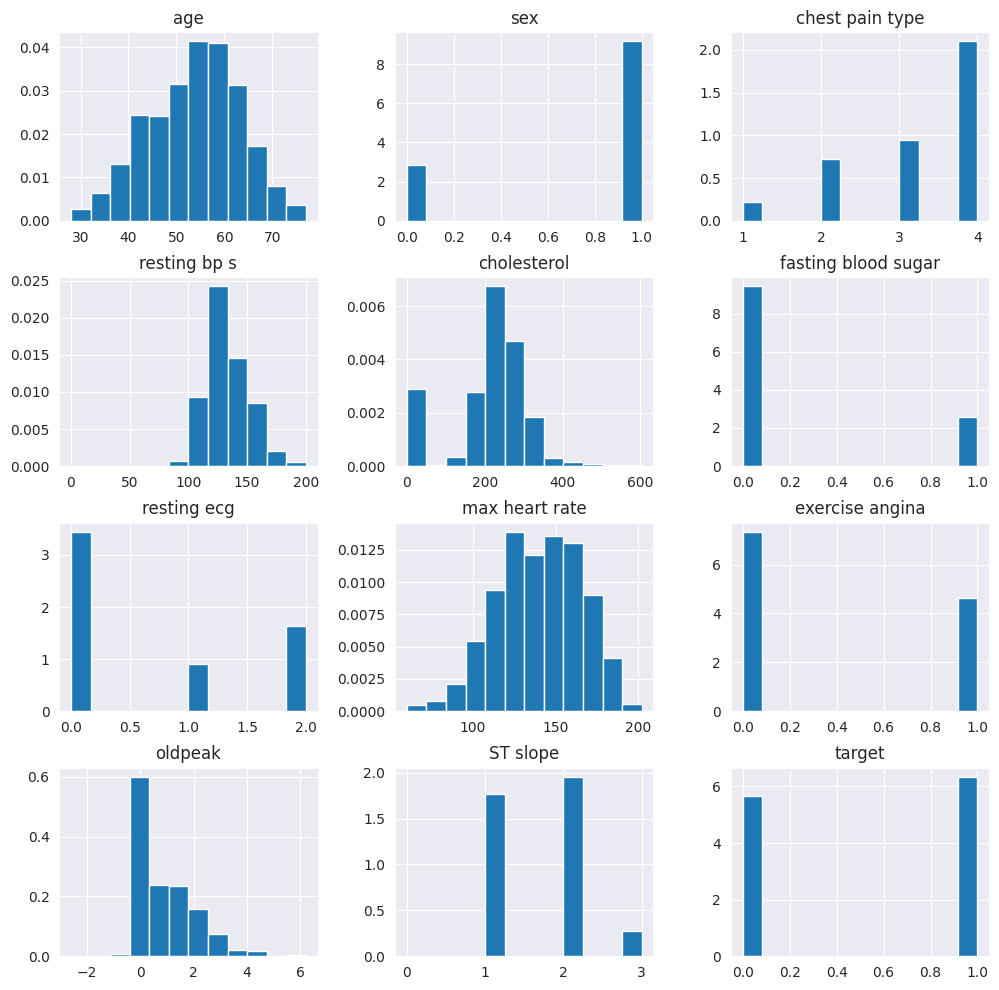

In [ ]:
# A General overview of the dataset

data.hist(bins=12, figsize=(12,12),density=True)
plt.show()

### Check for Types and Missing Values

In [ ]:
# Types and missing values
print("Missing values:",data.isna().sum().sum())
print()
data.info()

Missing values: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1190 entries, 0 to 1189
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1190 non-null   int64  
 1   sex                  1190 non-null   int64  
 2   chest pain type      1190 non-null   int64  
 3   resting bp s         1190 non-null   int64  
 4   cholesterol          1190 non-null   int64  
 5   fasting blood sugar  1190 non-null   int64  
 6   resting ecg          1190 non-null   int64  
 7   max heart rate       1190 non-null   int64  
 8   exercise angina      1190 non-null   int64  
 9   oldpeak              1190 non-null   float64
 10  ST slope             1190 non-null   int64  
 11  target               1190 non-null   int64  
dtypes: float64(1), int64(11)
memory usage: 111.7 KB


### Unique Values

In [ ]:
# Distinct values dictionary to map column names to unique values
# This can help with encoding downstream. For example, no need to one-hot encode binary nominal features

{column: len(data[column].unique())for column in data.columns}

{'age': 50,
 'sex': 2,
 'chest pain type': 4,
 'resting bp s': 67,
 'cholesterol': 222,
 'fasting blood sugar': 2,
 'resting ecg': 3,
 'max heart rate': 119,
 'exercise angina': 2,
 'oldpeak': 53,
 'ST slope': 4,
 'target': 2}

# Feature selection

### Split dataset

In [ ]:
 # Split df into X and y
y = data['target'].copy()
X = data.drop('target', axis=1).copy()

In [ ]:
columns = X.columns
print('X shape',X.shape)

X shape (1190, 11)


In [ ]:
y

,target
0,0
1,1
2,0
3,1
4,0
...,...
1185,1
1186,1
1187,1
1188,1


### Low Variance Filtering

Varience

age                       87.575960
sex                        0.180527
chest pain type            0.875124
resting bp s             337.413674
cholesterol            10286.115598
fasting blood sugar        0.168028
resting ecg                0.757525
max heart rate           651.149724
exercise angina            0.237520
oldpeak                    1.180129
ST slope                   0.372660
dtype: float64



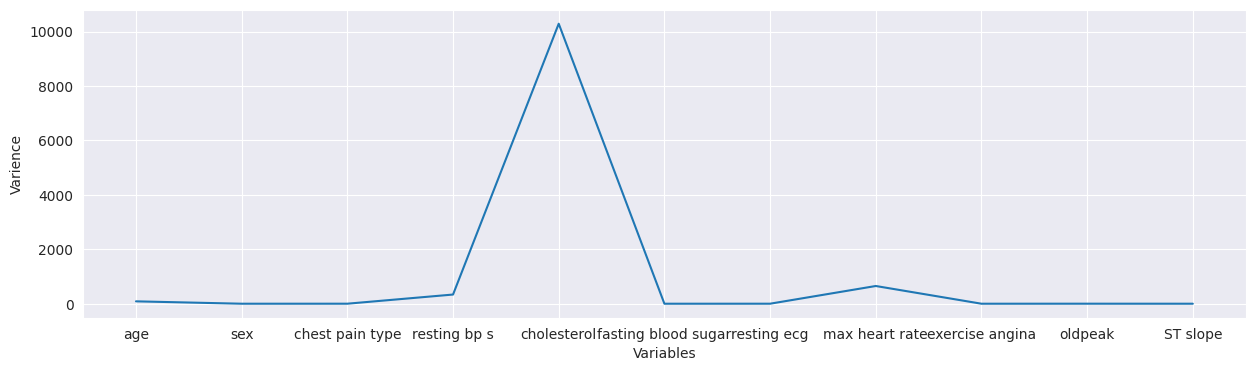

In [ ]:
# Dataset variences

variance = X.var()

print('Varience')
print()
print(X.var())

print()

plt.figure(figsize= (15,4))
plt.xlabel('Variables')
plt.ylabel('Varience')
plt.plot(variance)

###  Variables with variance more than the threshold value

In [ ]:
# Saving the names of variables having variance more than a threshold value
# In this case all original variable are retained

variable = [ ]

for i in range(0,len(variance)):
    if variance[i]>=0.006: #setting the threshold
        variable.append(columns[i])

variable

['age',
 'sex',
 'chest pain type',
 'resting bp s',
 'cholesterol',
 'fasting blood sugar',
 'resting ecg',
 'max heart rate',
 'exercise angina',
 'oldpeak',
 'ST slope']

### New dataframe using the above variables

In [ ]:
# creating a new dataframe using the above variables

new_data = X[variable]
print('new_data shape',new_data.shape)
new_data.head()

new_data shape (1190, 11)


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope
0,40,1,2,140,289,0,0,172,0,0.0,1
1,49,0,3,160,180,0,0,156,0,1.0,2
2,37,1,2,130,283,0,1,98,0,0.0,1
3,48,0,4,138,214,0,0,108,1,1.5,2
4,54,1,3,150,195,0,0,122,0,0.0,1


age                       87.575960
sex                        0.180527
chest pain type            0.875124
resting bp s             337.413674
cholesterol            10286.115598
fasting blood sugar        0.168028
resting ecg                0.757525
max heart rate           651.149724
exercise angina            0.237520
oldpeak                    1.180129
ST slope                   0.372660
dtype: float64



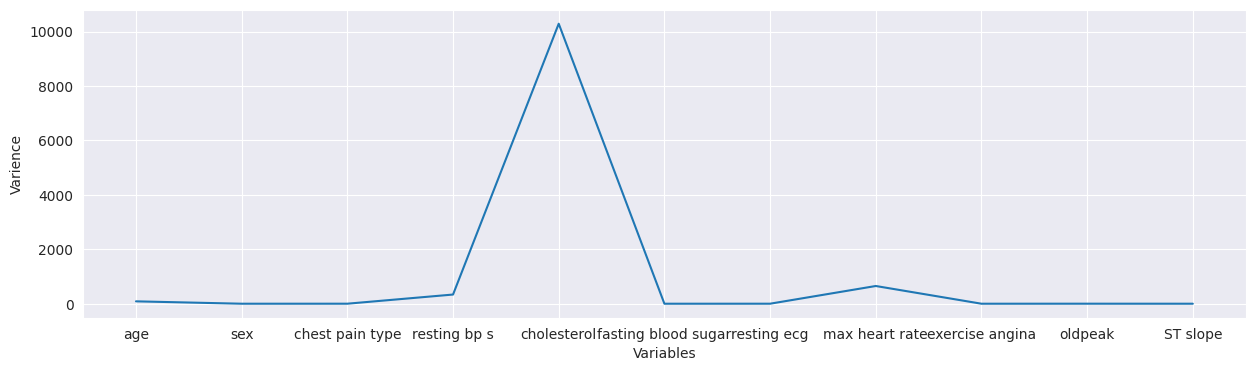

In [ ]:
# Data variences

new_data_var = new_data.var()
print(new_data_var)

print()

plt.figure(figsize= (15,4))
plt.xlabel('Variables')
plt.ylabel('Varience')
plt.plot(new_data_var)

No change from the original dataset. All variables are within the threshold

## Variable encoding

In [ ]:
# One Hot Encoding
# Use for larger dataset

def onehot_encode(X, column_dict):
    X = new_data.copy()
    for column, prefix in column_dict.items():
        dummies = pd.get_dummies(X[column], prefix=prefix)
        X = pd.concat([X, dummies], axis=1)
        X = X.drop(column, axis=1)

    return X


# Encoding

def preprocess_inputs(X): #, scaler
    X = new_data.copy()

    # One-hot encode the nominal features

    nominal_features = ['chest pain type','resting ecg','ST slope']
    X = onehot_encode(X, dict(zip(nominal_features, ['CPType','ECG','SLP'])))


    return X


In [ ]:
# Check Encoded feature

X = preprocess_inputs(new_data)
print(X.shape)
X

(1190, 19)


,age,sex,resting bp s,cholesterol,fasting blood sugar,max heart rate,exercise angina,oldpeak,CPType_1,CPType_2,CPType_3,CPType_4,ECG_0,ECG_1,ECG_2,SLP_0,SLP_1,SLP_2,SLP_3
0,40,1,140,289,0,172,0,0.0,False,True,False,False,True,False,False,False,True,False,False
1,49,0,160,180,0,156,0,1.0,False,False,True,False,True,False,False,False,False,True,False
2,37,1,130,283,0,98,0,0.0,False,True,False,False,False,True,False,False,True,False,False
3,48,0,138,214,0,108,1,1.5,False,False,False,True,True,False,False,False,False,True,False
4,54,1,150,195,0,122,0,0.0,False,False,True,False,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1185,45,1,110,264,0,132,0,1.2,True,False,False,False,True,False,False,False,False,True,False
1186,68,1,144,193,1,141,0,3.4,False,False,False,True,True,False,False,False,False,True,False
1187,57,1,130,131,0,115,1,1.2,False,False,False,True,True,False,False,False,False,True,False
1188,57,0,130,236,0,174,0,0.0,False,True,False,False,False,False,True,False,False,True,False


In [ ]:
y

,target
0,0
1,1
2,0
3,1
4,0
...,...
1185,1
1186,1
1187,1
1188,1


### Class distributions

In [ ]:
#Class distributions

# label encode the target variable
y = LabelEncoder().fit_transform(y)

# summarize distribution
counter = Counter(y)
for k,v in counter.items():
    per = v / len(y) * 100
    print('Class=%d, n=%d (%.3f%%)' % (k, v, per))

Class=0, n=561 (47.143%)
Class=1, n=629 (52.857%)


### Synthetic Minority Oversampling Technique
Optional: classes are fairly well distributed

In [ ]:
#SMOTE

# label encode the target variable
#y = LabelEncoder().fit_transform(y)

# transform the dataset
oversample = SMOTE()
X, y = oversample.fit_resample(X, y)

# summarize distribution
counter = Counter(y)
for k,v in counter.items():
    per = v / len(y) * 100
    print('Class=%d, n=%d (%.3f%%)' % (k, v, per))

Class=0, n=629 (50.000%)
Class=1, n=629 (50.000%)


## Model Definition and Training

In [ ]:
# Class label mapping

class_label = {
    0: 'No Heart Disease',
    1: 'Heart Disease'
}

### Train Test Split

In [ ]:
# Using 90% for training and 10% for testing
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.9,random_state=42)

In [ ]:
X_train.shape

(1132, 19)

In [ ]:
X_test.shape

(126, 19)

## Scaling

In [ ]:
#StandardScaler, MinMaxScaler, RobustScaler
#from sklearn.preprocessing import StandardScaler

#scaler = StandardScaler()
scaler = MinMaxScaler()
#scaler = RobustScaler()


# Fit on training set only.
scaler.fit(X_train)

# Apply transform to both the training set and the test set.
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Dummy Classifier

In [ ]:
# Dummy Classifier for baseline
from sklearn.dummy import DummyClassifier

dummy= DummyClassifier(strategy='stratified',random_state=42)
dummy.fit(X_train,y_train)

pred_dum= dummy.predict(X_test)
pred2_dum= dummy.predict(X_train)

# Matthews correlation, f1 score and accuracy

dummy_mcc_train = matthews_corrcoef(y_train, pred2_dum)
print('MCC on train:',dummy_mcc_train.round(3))
dummy_mcc_test = matthews_corrcoef(y_test,pred_dum)
print('MCC on test:',dummy_mcc_test.round(3))

print()
dummy_f1_train = f1_score(y_train,pred2_dum,average='macro')
print('F1 on train:', round(dummy_f1_train, 3))
dummy_f1_test = f1_score(y_test, pred_dum, average='macro')
print('F1 on test:', round(dummy_f1_test, 3))


print()

dum_acc_train = accuracy_score(y_train, pred2_dum)
dum_acc_test = accuracy_score(y_test,pred_dum)

print('Accuracy on train:', round(dum_acc_train, 3))
print('Accuracy on test:', round(dum_acc_test, 3))


#print('Accuracy on train:',dummy.score(X_train,y_train).round(3))
#print('Accuracy on test:',dummy.score(X_test,y_test).round(3))
print()
print('Confusion Matrix:\n{}'.format(confusion_matrix(y_test,pred_dum).round(3)))
print()
dummy.get_params()

MCC on train: -0.043
MCC on test: 0.053

F1 on train: 0.479
F1 on test: 0.523

Accuracy on train: 0.479
Accuracy on test: 0.524

Confusion Matrix:
[[35 35]
 [25 31]]



{'constant': None, 'random_state': 42, 'strategy': 'stratified'}

In [ ]:
# Cross Validation

scores=cross_val_score(dummy,X_train,y_train,cv=10,n_jobs=-1)
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

50.62% accuracy with a standard deviation of 4.57%


In [ ]:
print("dummy:",classification_report(y_test, pred_dum))

dummy:               precision    recall  f1-score   support

           0       0.58      0.50      0.54        70
           1       0.47      0.55      0.51        56

    accuracy                           0.52       126
   macro avg       0.53      0.53      0.52       126
weighted avg       0.53      0.52      0.53       126



Text(0.5, 23.52222222222222, 'Predicted Class')

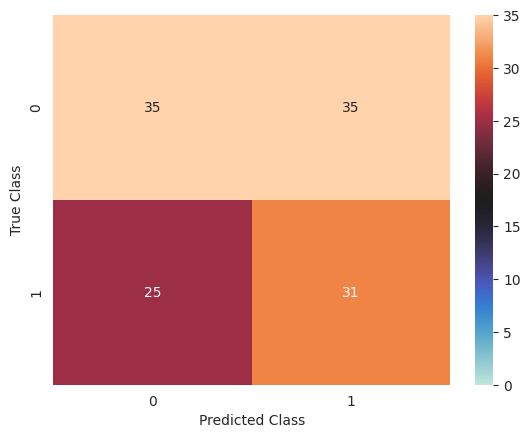

In [ ]:
cm = confusion_matrix(y_test,pred_dum)

#plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='icefire')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.55357143 0.5       ]
Specificity Mean: 0.5267857142857143
Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.5        0.55357143]
Recall/Sensitivity Mean: 0.5267857142857143
Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.58333333 0.46969697]
Precision Mean: 0.5265151515151516
Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.44642857 0.5       ]
False Positive Rate Mean: 0.4732142857142857
Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.5        0.44642857]
False Negative Rate Mean: 0.4732142857142857
Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.41666667 0.53030303]
False Discovery Rate Mean: 0.4734848484848485


### ROC Plot

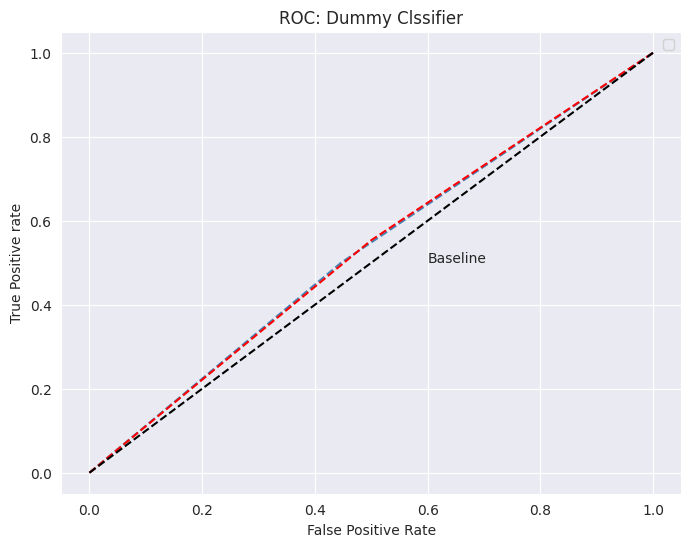

In [ ]:
#ROC Plot
#from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = dummy.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue')#, label='No Heart Disease 0'
plt.plot(fpr[1], tpr[1], linestyle='--',color='red')#, label='Heart Disease 1'
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: Dummy Clssifier')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('Dummy ROC',dpi=300);

### AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
dummy_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('Dummy AUC Score:',dummy_auc_score)

Dummy AUC Score: 0.5268


## Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

# Train Logistic Regression model
lr = LogisticRegression(
    n_jobs=-1,
    solver='lbfgs',
    random_state=42,
    max_iter=1000
).fit(X_train, y_train)

# Predictions
pred_lr = lr.predict(X_test)
pred2_lr = lr.predict(X_train)

# Matthews Correlation Coefficient
lr_mcc_train = matthews_corrcoef(y_train, pred2_lr)
lr_mcc_test = matthews_corrcoef(y_test, pred_lr)

print('MCC on train:', round(lr_mcc_train, 3))
print('MCC on test:', round(lr_mcc_test, 3))

print()

# F1 Score
lr_f1_train = f1_score(y_train, pred2_lr, average='macro')
lr_f1_test = f1_score(y_test, pred_lr, average='macro')

print('F1 on train:', round(lr_f1_train, 3))
print('F1 on test:', round(lr_f1_test, 3))

print()

# Accuracy
lr_acc_train = accuracy_score(y_train, pred2_lr)
lr_acc_test = accuracy_score(y_test, pred_lr)

print('Accuracy on train:', round(lr_acc_train, 3))
print('Accuracy on test:', round(lr_acc_test, 3))

print()

# Confusion Matrix
print('Confusion Matrix:')
print(confusion_matrix(y_test, pred_lr))

print()
print('Logistic Regression Model Parameters:')
print(lr.get_params())

MCC on train: 0.707
MCC on test: 0.7

F1 on train: 0.853
F1 on test: 0.848

Accuracy on train: 0.853
Accuracy on test: 0.849

Confusion Matrix:
[[58 12]
 [ 7 49]]

Logistic Regression Model Parameters:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': -1, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [ ]:
# Cross Validation

scores=cross_val_score(lr,X_train,y_train,cv=10,n_jobs=-1)
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

84.98% accuracy with a standard deviation of 2.74%


In [ ]:
print("lr:",classification_report(y_test, pred_lr))

lr:               precision    recall  f1-score   support

           0       0.89      0.83      0.86        70
           1       0.80      0.88      0.84        56

    accuracy                           0.85       126
   macro avg       0.85      0.85      0.85       126
weighted avg       0.85      0.85      0.85       126



Text(0.5, 23.52222222222222, 'Predicted Class')

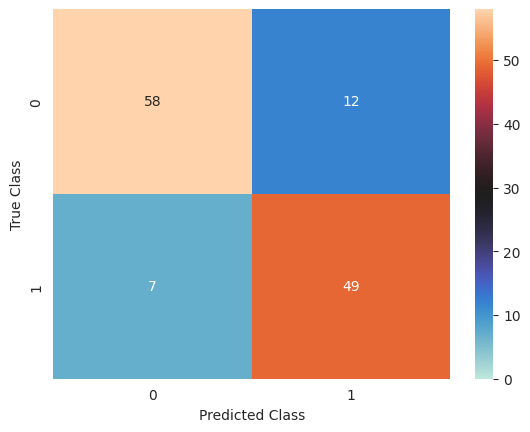

In [ ]:
cm = confusion_matrix(y_test,pred_lr)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='icefire') #removed 'crest_r'
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.875      0.82857143]
Specificity Mean: 0.8517857142857144

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.82857143 0.875     ]
Recall/Sensitivity Mean: 0.8517857142857144

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.89230769 0.80327869]
Precision Mean: 0.8477931904161413

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.125      0.17142857]
False Positive Rate Mean: 0.14821428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.17142857 0.125     ]
False Negative Rate Mean: 0.14821428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.10769231 0.19672131]
False Discovery Rate Mean: 0.15220680958385877


### ROC Plot

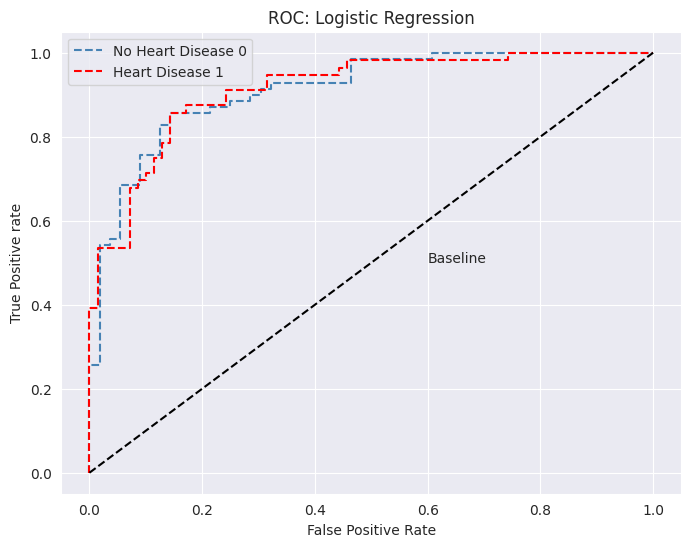

In [ ]:
#ROC Plot
#from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = lr.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: Logistic Regression')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('LR ROC',dpi=300);

### AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
lr_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('Logistic Regression AUC Score:',lr_auc_score)

Logistic Regression AUC Score: 0.9133


## Predictions and Confidence Interval

### Index of  incorrect predictions

In [ ]:
# Incorrect predictions

prediction_cplx = lr.predict(X_test)

incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,   9,  11,  14,  16,  20,  32,  35,  43,  44,  56,  59,  74,
        100, 107, 110, 111, 121, 122]),)

### Classes and probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = lr.predict_proba(X_test)
prediction_cplx = lr.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df

,No heart disease,Heart disease,Predicted class
0,0.894,0.106,0
1,0.595,0.405,0
2,0.218,0.782,1
3,0.092,0.908,1
4,0.633,0.367,0
...,...,...,...
121,0.494,0.506,1
122,0.857,0.143,0
123,0.954,0.046,0
124,0.060,0.940,1


### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class


jaccard = jaccard_score(y_test, prediction_cplx, average = None)

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.753247
1,0.720588


### Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

#### Using model error

In [ ]:
X_test.shape

(126, 19)

In [ ]:
# 95% confidence interval (z = 1.96) See above

# calculated radius of the confidence interval (error)

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.08 * (1 - 0.08)) / 119)
print('Confidence interval radius:%.3f' % interval)

Confidence interval radius:0.049


* **The classification error of the model is 8%, +/- 5%**
* **The true classification error of the model is likely between 3% and 13%**.

* **The true model skill may lie outside of this range**.


### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy (95% confidence) using 53 correct predictions,
# out of a dataset of 61 instances and 95% conficence interval

# from statsmodels.stats.proportion import proportion_confint

lower, upper = proportion_confint(109,119,0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.866 
Upper Bounds of Accuracy:0.966 


* **Using 95% confidence interval**
* **The true classification accuracy of the logistic regression model is likely between 87% and 97%**


## Decision Tree

In [ ]:
# Decision Tree

dt = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
).fit(X_train, y_train)

# Predictions
pred_dt = dt.predict(X_test)
pred2_dt = dt.predict(X_train)

# Matthews Correlation Coefficient
dt_mcc_train = matthews_corrcoef(y_train, pred2_dt)
dt_mcc_test = matthews_corrcoef(y_test, pred_dt)

print('MCC on train:', round(dt_mcc_train, 3))
print('MCC on test:', round(dt_mcc_test, 3))

print()

# F1 Score
dt_f1_train = f1_score(y_train, pred2_dt, average='macro')
dt_f1_test = f1_score(y_test, pred_dt, average='macro')

print('F1 on train:', round(dt_f1_train, 3))
print('F1 on test:', round(dt_f1_test, 3))

print()

# Accuracy
dt_acc_train = accuracy_score(y_train, pred2_dt)
dt_acc_test = accuracy_score(y_test, pred_dt)

print('Accuracy on train:', round(dt_acc_train, 3))
print('Accuracy on test:', round(dt_acc_test, 3))

print()

# Confusion Matrix
print('Confusion Matrix:')
print(confusion_matrix(y_test, pred_dt))

print()

# Model Parameters
print('Decision Tree Model Parameters:')
print(dt.get_params())

MCC on train: 0.806
MCC on test: 0.695

F1 on train: 0.902
F1 on test: 0.845

Accuracy on train: 0.902
Accuracy on test: 0.849

Confusion Matrix:
[[64  6]
 [13 43]]

Decision Tree Model Parameters:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 6, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


In [ ]:
# Cross Validation

scores=cross_val_score(dt,X_train,y_train,cv=10,n_jobs=-1,scoring='f1')
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

85.73% accuracy with a standard deviation of 3.89%


In [ ]:
print("dt:",classification_report(y_test, pred_dt))

dt:               precision    recall  f1-score   support

           0       0.83      0.91      0.87        70
           1       0.88      0.77      0.82        56

    accuracy                           0.85       126
   macro avg       0.85      0.84      0.84       126
weighted avg       0.85      0.85      0.85       126



Text(0.5, 23.52222222222222, 'Predicted Class')

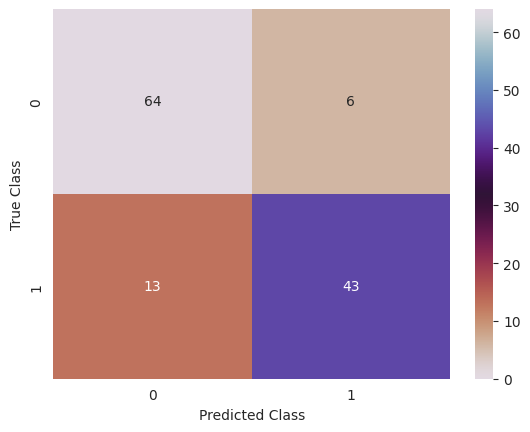

In [ ]:
cm = confusion_matrix(y_test,pred_dt)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='twilight_r')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.76785714 0.91428571]
Specificity Mean: 0.8410714285714286

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.91428571 0.76785714]
Recall/Sensitivity Mean: 0.8410714285714286

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.83116883 0.87755102]
Precision Mean: 0.8543599257884973

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.23214286 0.08571429]
False Positive Rate Mean: 0.15892857142857142

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.08571429 0.23214286]
False Negative Rate Mean: 0.15892857142857142

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.16883117 0.12244898]
False Discovery Rate Mean: 0.14564007421150277


### ROC Plot

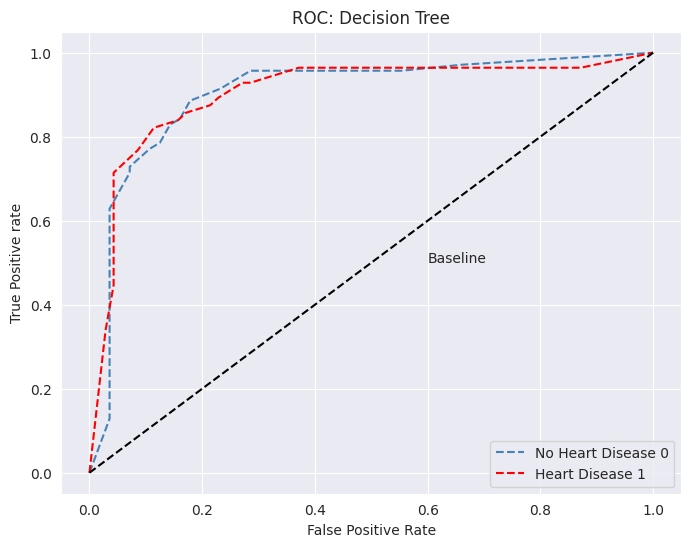

In [ ]:
#ROC Plot
#from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = dt.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: Decision Tree')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('DT ROC',dpi=300);

###  AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
dt_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('Decision Tree AUC Score:',dt_auc_score)

Decision Tree AUC Score: 0.9042


## Predictions and Confidence Interval

### Index of  incorrect predictions

In [ ]:
# Incorrect predictions

prediction_cplx = dt.predict(X_test)

incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,   7,   9,  15,  32,  36,  43,  44,  53,  56,  59,  61,  74,
         99, 107, 110, 111, 115, 122]),)

### Classes and probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = dt.predict_proba(X_test)
prediction_cplx = dt.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df

,No heart disease,Heart disease,Predicted class
0,0.992,0.008,0
1,1.000,0.000,0
2,0.350,0.650,1
3,0.063,0.937,1
4,1.000,0.000,0
...,...,...,...
121,0.509,0.491,0
122,0.667,0.333,0
123,0.992,0.008,0
124,0.063,0.937,1


### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class


jaccard = jaccard_score(y_test, prediction_cplx, average = None)

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.771084
1,0.693548


### Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

#### Using model error

In [ ]:
# 95% confidence interval (z = 1.96) See above

# calculated radius of the confidence interval (error)

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.13 * (1 - 0.13)) / 119)
print('Confidence interval radius:%.3f' % interval)

Confidence interval radius:0.060


* **The classification error of the model is 13%, +/- 6%**
* **The true classification error of the model is likely between 7% and 19%**.

* **True model skill may lie outside of this range**.

### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy (95% confidence) using 26 correct predictions,
# out of a dataset of 33 instances and 95% conficence interval

# from statsmodels.stats.proportion import proportion_confint

lower, upper = proportion_confint(104, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.814 
Upper Bounds of Accuracy:0.934 



  
* **The true classification accuracy of the model is likely between 81% and 93%**.

* **True model skill may lie outside of this range**.

## Feature Importances

In [ ]:
ft_1=pd.DataFrame({'Features':X.columns,'Importances':dt.feature_importances_})
ft_1=ft_1.sort_values(by='Importances',ascending=False)
ft_1

,Features,Importances
16,SLP_1,0.490522
11,CPType_4,0.147745
2,resting bp s,0.065920
1,sex,0.065211
7,oldpeak,0.047567
5,max heart rate,0.047033
6,exercise angina,0.039157
3,cholesterol,0.034348
4,fasting blood sugar,0.032012
0,age,0.012437


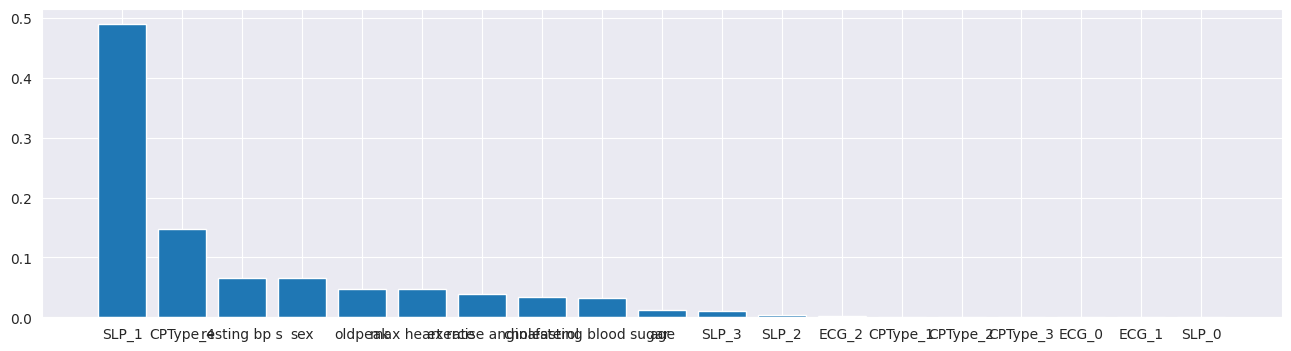

               Features  Importances
16                SLP_1     0.490522
11             CPType_4     0.147745
2          resting bp s     0.065920
1                   sex     0.065211
7               oldpeak     0.047567
5        max heart rate     0.047033
6       exercise angina     0.039157
3           cholesterol     0.034348
4   fasting blood sugar     0.032012
0                   age     0.012437
18                SLP_3     0.011034
17                SLP_2     0.004062
14                ECG_2     0.002952
8              CPType_1     0.000000
9              CPType_2     0.000000
10             CPType_3     0.000000
12                ECG_0     0.000000
13                ECG_1     0.000000
15                SLP_0     0.000000


In [ ]:
# Features Plot and list
ft_1=pd.DataFrame({'Features':X.columns,'Importances':dt.feature_importances_})
ft_1=ft_1.sort_values(by='Importances',ascending=False)

# Features plot

plt.figure(figsize=(16,4))
plt.bar(ft_1['Features'],ft_1['Importances'])
plt.show()
print(ft_1)

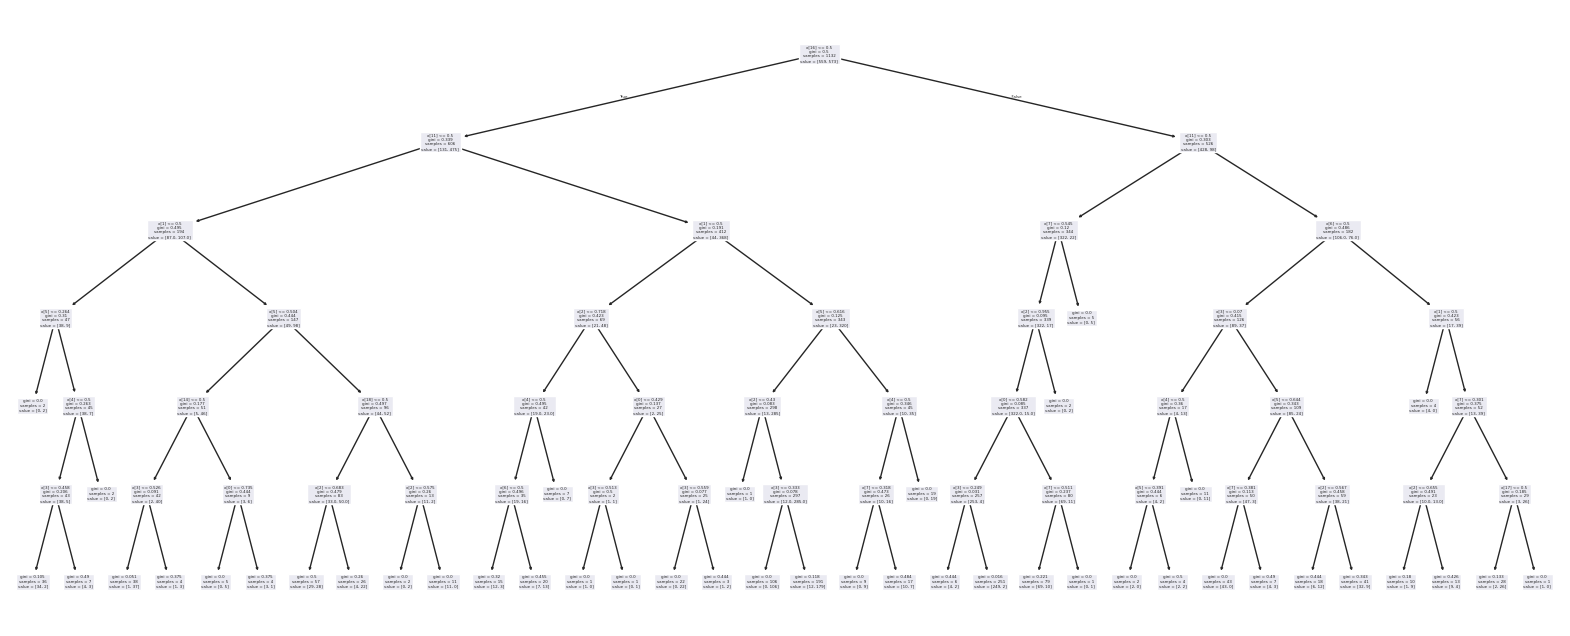

In [ ]:
# Tree plot

from sklearn import tree
plt.figure(figsize=(20,8))
tree.plot_tree(dt)
#plt.savefig('dt.png')
plt.show()

## Random Forest Classifier

In [ ]:
# Random Forest

rf = RandomForestClassifier(
    n_estimators=10,
    n_jobs=-1,
    criterion='entropy',
    random_state=42
)

rf.fit(X_train, y_train)

# Predictions
pred_rf = rf.predict(X_test)
pred2_rf = rf.predict(X_train)

# Matthews Correlation Coefficient
rf_mcc_train = matthews_corrcoef(y_train, pred2_rf)
rf_mcc_test = matthews_corrcoef(y_test, pred_rf)

print('MCC on train:', round(rf_mcc_train, 3))
print('MCC on test:', round(rf_mcc_test, 3))

print()

# F1 Score
rf_f1_train = f1_score(y_train, pred2_rf, average='macro')
rf_f1_test = f1_score(y_test, pred_rf, average='macro')

print('F1 on train:', round(rf_f1_train, 3))
print('F1 on test:', round(rf_f1_test, 3))

print()

# Accuracy
rf_acc_train = accuracy_score(y_train, pred2_rf)
rf_acc_test = accuracy_score(y_test, pred_rf)

print('Accuracy on train:', round(rf_acc_train, 3))
print('Accuracy on test:', round(rf_acc_test, 3))

print()

# Confusion Matrix
print('Confusion Matrix:')
print(confusion_matrix(y_test, pred_rf))

print()

# Model Parameters
print('Random Forest Model Parameters:')
print(rf.get_params())

MCC on train: 0.991
MCC on test: 0.791

F1 on train: 0.996
F1 on test: 0.895

Accuracy on train: 0.996
Accuracy on test: 0.897

Confusion Matrix:
[[65  5]
 [ 8 48]]

Random Forest Model Parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 10, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


### Cross validation

In [ ]:
# Cross Validation

scores=cross_val_score(rf,X_train,y_train,cv=10,n_jobs=-1,scoring='f1')
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

92.68% accuracy with a standard deviation of 2.30%


### Classification report

In [ ]:
print("rf:",classification_report(y_test, pred_rf))

rf:               precision    recall  f1-score   support

           0       0.89      0.93      0.91        70
           1       0.91      0.86      0.88        56

    accuracy                           0.90       126
   macro avg       0.90      0.89      0.89       126
weighted avg       0.90      0.90      0.90       126



### Confusion matrix

Text(0.5, 23.52222222222222, 'Predicted Class')

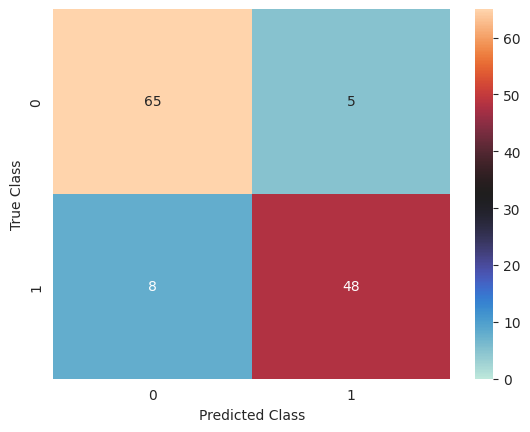

In [ ]:
cm = confusion_matrix(y_test,pred_rf)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='icefire')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.85714286 0.92857143]
Specificity Mean: 0.8928571428571428

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.92857143 0.85714286]
Recall/Sensitivity Mean: 0.8928571428571428

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.89041096 0.90566038]
Precision Mean: 0.8980356681313001

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.14285714 0.07142857]
False Positive Rate Mean: 0.10714285714285714

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.07142857 0.14285714]
False Negative Rate Mean: 0.10714285714285714

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.10958904 0.09433962]
False Discovery Rate Mean: 0.10196433186869992


### ROC Plot

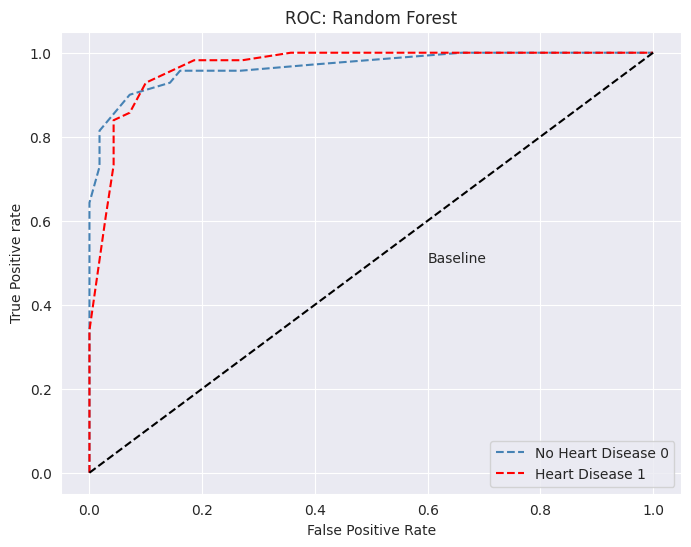

In [ ]:
#ROC Plot
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = rf.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: Random Forest')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('RF ROC',dpi=300);

### AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
rf_auc_score = roc_auc_score(y_test, prediction_cplx[:,i])

print('Random Forest AUC Score:',rf_auc_score)

Random Forest AUC Score: 0.9667091836734695


## Predictions and Confidences
 **Classes and Probabilities**

In [ ]:
# Classes and Probabilities

prediction_probability = rf.predict_proba(X_test)
prediction_cplx = rf.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])

#pred_list = pd.concat(['frame','target_rs'],axis= 1)


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df

,No heart disease,Heart disease,Predicted class
0,1.0,0.0,0
1,0.9,0.1,0
2,0.5,0.5,0
3,0.0,1.0,1
4,1.0,0.0,0
...,...,...,...
121,0.7,0.3,0
122,0.2,0.8,1
123,1.0,0.0,0
124,0.0,1.0,1


In [ ]:
# Incorrect predictions

prediction_cplx = rf.predict(X_test)

incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  2,   5,  15,  20,  43,  56,  59,  61,  65,  74, 110, 111, 115]),)

### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class


jaccard = jaccard_score(y_test, prediction_cplx, average = None) #prediction_probability

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.833333
1,0.786885


## Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

### Using model error

In [ ]:
# 95% confidence interval
# Calculated radius of the confidence interval using model error

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.06 * (1 - .06)) / 119)
print('Classification error interval: %.3f' % interval)

Classification error interval: 0.043


* The classification error of the model is 6% +/- 4%
* The true classification error of the model on unseen data is likely between 2% and 10%.

 **The true model skill may lie outside of this range.**

### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy

# 218 correct predictions of 238 instances and with 95% confidence interval,
# (provided to the function as a significance of 0.05)

lower, upper = proportion_confint(112, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.899 
Upper Bounds of Accuracy:0.983 


 **The true classification accuracy of the model on unseen data is likely between 90% and 98%**.

 **True model skill may lie outside of this range.**

### Feature Importances

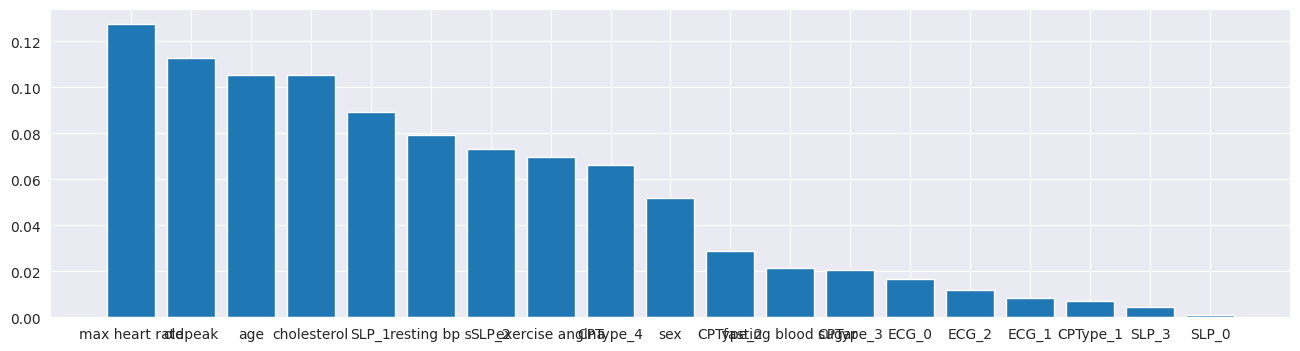

               Features  Importances
5        max heart rate     0.127536
7               oldpeak     0.112681
0                   age     0.105223
3           cholesterol     0.105125
16                SLP_1     0.089407
2          resting bp s     0.079227
17                SLP_2     0.073016
6       exercise angina     0.069744
11             CPType_4     0.066155
1                   sex     0.051733
9              CPType_2     0.028668
4   fasting blood sugar     0.021286
10             CPType_3     0.020351
12                ECG_0     0.016689
14                ECG_2     0.011948
13                ECG_1     0.008498
8              CPType_1     0.007004
18                SLP_3     0.004686
15                SLP_0     0.001024


In [ ]:
# Features Plot and list
ft_1=pd.DataFrame({'Features':X.columns,'Importances':rf.feature_importances_})
ft_1=ft_1.sort_values(by='Importances',ascending=False)

# Features plot

plt.figure(figsize=(16,4))
plt.bar(ft_1['Features'],ft_1['Importances'])
plt.show()
print(ft_1)

## XGBoost

In [ ]:
# XGBoost

evalset = [
    (X_train, y_train),
    (X_test, y_test)
]

xgb = XGBClassifier(
    max_depth=10,
    gamma=0.6,
    n_jobs=-1,
    booster="gbtree",
    eval_metric=["logloss", "error"],
    objective="binary:logistic",
    random_state=42
)

# Train model
xgb.fit(
    X_train,
    y_train,
    eval_set=evalset,
    verbose=False
)

# Predictions
pred_xgb = xgb.predict(X_test)
pred2_xgb = xgb.predict(X_train)

# Matthews Correlation Coefficient
xgb_mcc_train = matthews_corrcoef(y_train, pred2_xgb)
xgb_mcc_test = matthews_corrcoef(y_test, pred_xgb)

print('MCC on train:', round(xgb_mcc_train, 3))
print('MCC on test:', round(xgb_mcc_test, 3))

print()

# F1 Score
xgb_f1_train = f1_score(y_train, pred2_xgb, average='macro')
xgb_f1_test = f1_score(y_test, pred_xgb, average='macro')

print('F1 on train:', round(xgb_f1_train, 3))
print('F1 on test:', round(xgb_f1_test, 3))

print()

# Accuracy
xgb_acc_train = accuracy_score(y_train, pred2_xgb)
xgb_acc_test = accuracy_score(y_test, pred_xgb)

print('Accuracy on train:', round(xgb_acc_train, 3))
print('Accuracy on test:', round(xgb_acc_test, 3))

print()

# Confusion Matrix
print('Confusion Matrix:')
print(confusion_matrix(y_test, pred_xgb))

print()

# Model Parameters
print('XGBoost Model Parameters:')
print(xgb.get_params())

MCC on train: 0.984
MCC on test: 0.839

F1 on train: 0.992
F1 on test: 0.92

Accuracy on train: 0.992
Accuracy on test: 0.921

Confusion Matrix:
[[65  5]
 [ 5 51]]

XGBoost Model Parameters:
{'objective': 'binary:logistic', 'base_score': None, 'booster': 'gbtree', 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': ['logloss', 'error'], 'feature_types': None, 'feature_weights': None, 'gamma': 0.6, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 10, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_m

### Learning curves

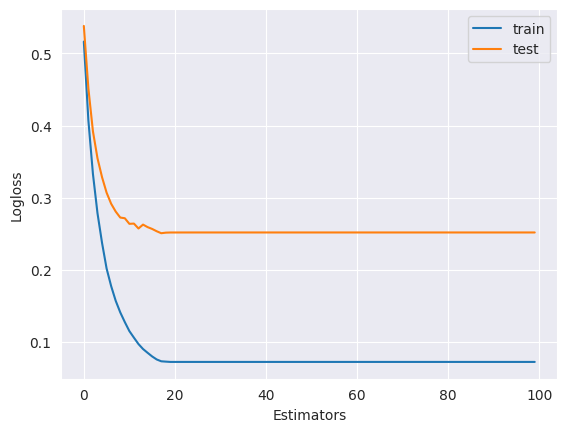

In [ ]:
# retrieve performance metrics
results = xgb.evals_result()

# plot learning curves
plt.plot(results['validation_0']['logloss'], label='train')
plt.plot(results['validation_1']['logloss'], label='test')
plt.ylabel('Logloss')
plt.xlabel('Estimators')
plt.legend()
plt.show()

### Cross validation

In [ ]:
# Cross Validation

scores=cross_val_score(xgb,X_train,y_train,cv=10,n_jobs=-1,scoring='f1')
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

91.51% accuracy with a standard deviation of 2.88%


### Classification report

In [ ]:
print("xgb:",classification_report(y_test, pred_xgb))

xgb:               precision    recall  f1-score   support

           0       0.93      0.93      0.93        70
           1       0.91      0.91      0.91        56

    accuracy                           0.92       126
   macro avg       0.92      0.92      0.92       126
weighted avg       0.92      0.92      0.92       126



### Confusion matrix

Text(0.5, 23.52222222222222, 'Predicted Class')

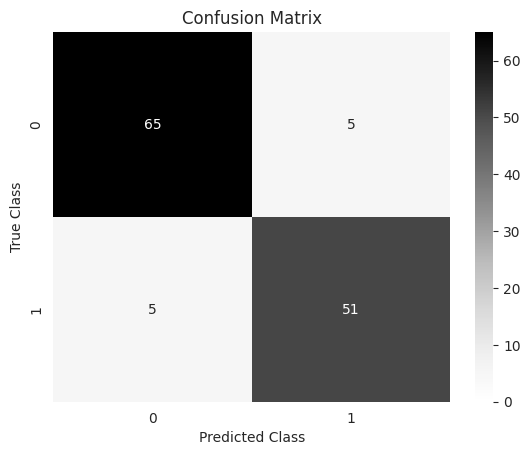

In [ ]:
cm = confusion_matrix(y_test,pred_xgb)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='Greys')
plt.title('Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.91071429 0.92857143]
Specificity Mean: 0.9196428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.92857143 0.91071429]
Recall/Sensitivity Mean: 0.9196428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.92857143 0.91071429]
Precision Mean: 0.9196428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.08928571 0.07142857]
False Positive Rate Mean: 0.08035714285714285

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.07142857 0.08928571]
False Negative Rate Mean: 0.08035714285714285

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.07142857 0.08928571]
False Discovery Rate Mean: 0.08035714285714285


### ROC Plot

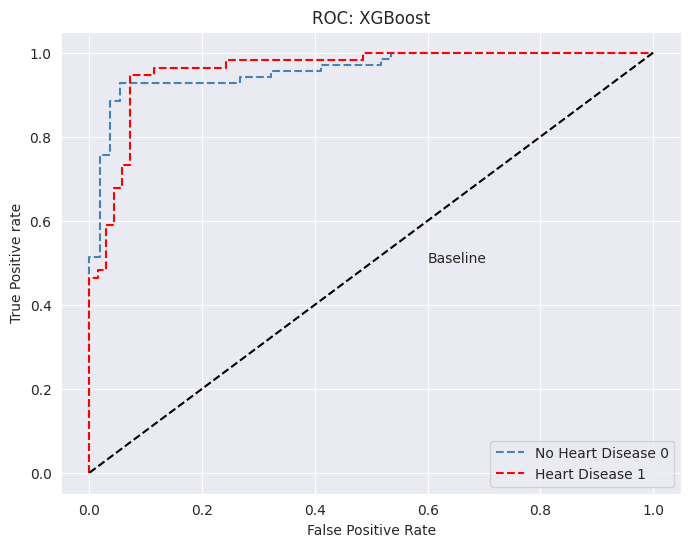

In [ ]:
#ROC Plot
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = xgb.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: XGBoost')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('XGB ROC',dpi=300);

### ROC AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
xgb_auc_score = roc_auc_score(y_test, prediction_cplx[:,i])

print('XGB AUC Score:',xgb_auc_score.round(3))

XGB AUC Score: 0.959


## Predictions and Confidences
 ### Classes and Probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = xgb.predict_proba(X_test)
prediction_cplx = xgb.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])

#pred_list = pd.concat(['frame','target_rs'],axis= 1)


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df.head()

,No heart disease,Heart disease,Predicted class
0,0.989,0.011,0
1,0.974,0.026,0
2,0.235,0.765,1
3,0.090,0.910,1
4,0.920,0.080,0


### Index of  incorrect predictions

In [ ]:
# Incorrect predictions

incorrects = np.where(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,  15,  36,  43,  56,  59,  61,  65,  74, 111]),)

### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class

jaccard = jaccard_score(y_test, prediction_cplx, average = None)#prediction_probability

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.866667
1,0.836066


## Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

### Using model error

In [ ]:
# 95% confidence interval
# Calculated radius of the confidence interval using model error

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.03 * (1 - .03)) / 119)
print('Classification error interval: %.3f' % interval)

Classification error interval: 0.031


* The classification error of the model is 3% +/- 3%
* The true classification error of the model on unseen data is likely between 0% and 6%.

 **The true model skill may lie outside of this range.**

### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy

# 218 correct predictions of 238 instances and with 95% confidence interval,
# (provided to the function as a significance of 0.05)

lower, upper = proportion_confint(115, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.934 
Upper Bounds of Accuracy:0.999 


 **The true classification accuracy of the model on unseen data is likely between 93% and 99.9%**.

 **True model skill may lie outside of this range.**

### Feature Importances

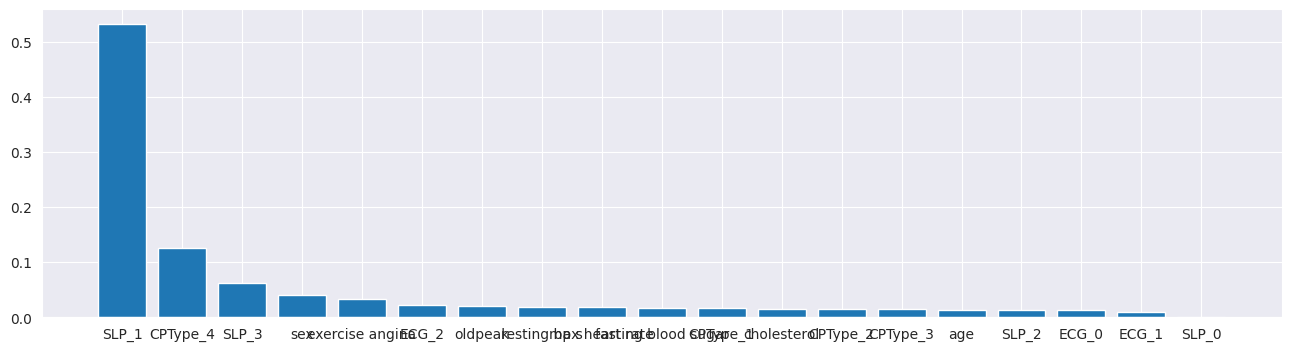

               Features  Importances
16                SLP_1     0.532058
11             CPType_4     0.125510
18                SLP_3     0.061633
1                   sex     0.040213
6       exercise angina     0.033672
14                ECG_2     0.021717
7               oldpeak     0.020295
2          resting bp s     0.018828
5        max heart rate     0.018559
4   fasting blood sugar     0.017508
8              CPType_1     0.016470
3           cholesterol     0.015823
9              CPType_2     0.014831
10             CPType_3     0.014148
0                   age     0.013417
17                SLP_2     0.012732
12                ECG_0     0.012597
13                ECG_1     0.009990
15                SLP_0     0.000000


In [ ]:
# Features Plot and list
ft_1=pd.DataFrame({'Features':X.columns,'Importances':xgb.feature_importances_})
ft_1=ft_1.sort_values(by='Importances',ascending=False)

# Features plot

plt.figure(figsize=(16,4))
plt.bar(ft_1['Features'],ft_1['Importances'])
plt.show()
print(ft_1)

## SVM

In [ ]:
# SVM

svm = SVC(
    C=1.0,
    kernel='poly',
    decision_function_shape='ovr',
    probability=True,
    degree=3,
    random_state=42
)

# Train model
svm.fit(X_train, y_train)

# Predictions
pred_svm = svm.predict(X_test)
pred2_svm = svm.predict(X_train)

# Matthews Correlation Coefficient
svm_mcc_train = matthews_corrcoef(y_train, pred2_svm)
svm_mcc_test = matthews_corrcoef(y_test, pred_svm)

print('MCC on train:', round(svm_mcc_train, 3))
print('MCC on test:', round(svm_mcc_test, 3))

print()

# F1 Score
svm_f1_train = f1_score(y_train, pred2_svm, average='macro')
svm_f1_test = f1_score(y_test, pred_svm, average='macro')

print('F1 on train:', round(svm_f1_train, 3))
print('F1 on test:', round(svm_f1_test, 3))

print()

# Accuracy
svm_acc_train = accuracy_score(y_train, pred2_svm)
svm_acc_test = accuracy_score(y_test, pred_svm)

print('Accuracy on train:', round(svm_acc_train, 3))
print('Accuracy on test:', round(svm_acc_test, 3))

print()

# Confusion Matrix
print('Confusion Matrix:')
print(confusion_matrix(y_test, pred_svm))

print()

# Model Parameters
print('SVM Model Parameters:')
print(svm.get_params())

MCC on train: 0.799
MCC on test: 0.712

F1 on train: 0.899
F1 on test: 0.856

Accuracy on train: 0.899
Accuracy on test: 0.857

Confusion Matrix:
[[60 10]
 [ 8 48]]

SVM Model Parameters:
{'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'poly', 'max_iter': -1, 'probability': True, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}


### Cross validation

In [ ]:
# Cross Validation

scores=cross_val_score(svm,X_train,y_train,cv=10,n_jobs=-1,scoring='f1')
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

86.74% accuracy with a standard deviation of 2.69%


### Classification report

In [ ]:
# Classification report
print("svm:",classification_report(y_test, pred_svm))

svm:               precision    recall  f1-score   support

           0       0.88      0.86      0.87        70
           1       0.83      0.86      0.84        56

    accuracy                           0.86       126
   macro avg       0.85      0.86      0.86       126
weighted avg       0.86      0.86      0.86       126



### Confusion matrix

Text(0.5, 23.52222222222222, 'Predicted Class')

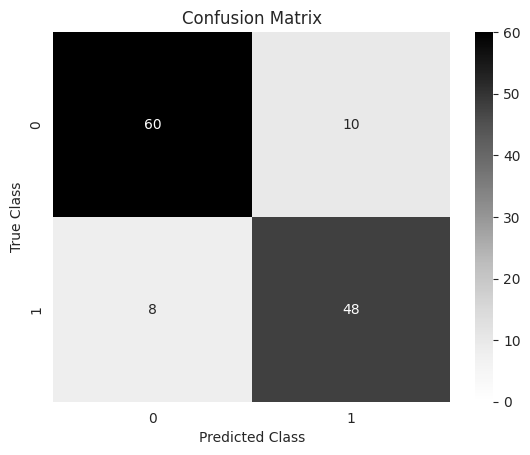

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test,pred_svm)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='Greys')
plt.title('Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.85714286 0.85714286]
Specificity Mean: 0.8571428571428571

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.85714286 0.85714286]
Recall/Sensitivity Mean: 0.8571428571428571

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.88235294 0.82758621]
Precision Mean: 0.8549695740365111

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.14285714 0.14285714]
False Positive Rate Mean: 0.14285714285714285

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.14285714 0.14285714]
False Negative Rate Mean: 0.14285714285714285

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.11764706 0.17241379]
False Discovery Rate Mean: 0.14503042596348886


### ROC Plot

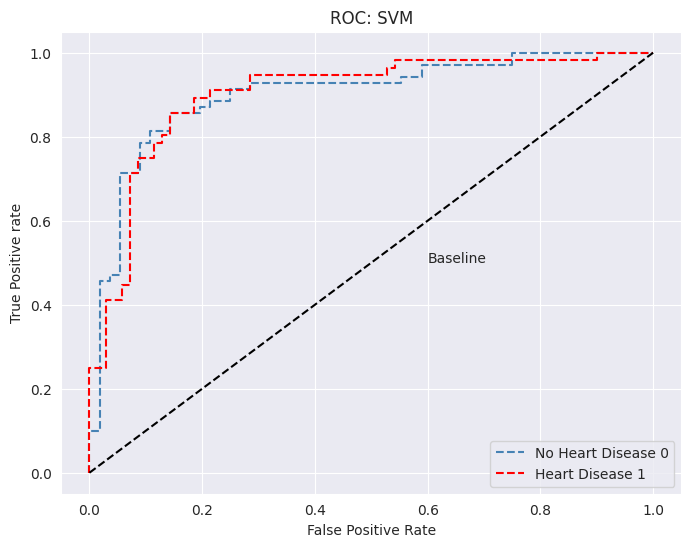

In [ ]:
#ROC Plot
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = svm.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: SVM')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('SVM ROC',dpi=300);

### ROC AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
svm_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('SVM AUC Score:',svm_auc_score)

SVM AUC Score: 0.9013


## Predictions and Confidences
 ### Classes and Probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = svm.predict_proba(X_test)
prediction_cplx = svm.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])

#pred_list = pd.concat(['frame','target_rs'],axis= 1)


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df.head()

,No heart disease,Heart disease,Predicted class
0,0.837,0.163,0
1,0.834,0.166,0
2,0.188,0.812,1
3,0.132,0.868,1
4,0.928,0.072,0


### Index of  incorrect predictions

In [ ]:
# Incorrect predictions

incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,   9,  15,  16,  20,  32,  36,  43,  47,  56,  59,  74, 100,
        106, 107, 110, 111, 122]),)

### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class

jaccard = jaccard_score(y_test, prediction_cplx, average = None)#prediction_probability

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.769231
1,0.727273


## Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

### Using model error

In [ ]:
# 95% confidence interval
# Calculated radius of the confidence interval using model error

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.08 * (1 - .08)) / 119)
print('Classification error interval: %.3f' % interval)

Classification error interval: 0.049


* The classification error of the model is 8% +/- 5%
* The true classification error of the model on unseen data is likely between 3% and 13%.

 **The true model skill may lie outside of this range.**

### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy

# 218 correct predictions of 238 instances and with 95% confidence interval,
# (provided to the function as a significance of 0.05)

lower, upper = proportion_confint(109, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.866 
Upper Bounds of Accuracy:0.966 


 **The true classification accuracy of the model on unseen data is likely between 87% and 97%**.

 **True model skill may lie outside of this range.**

### KNN

In [ ]:
# KNN

knn = KNeighborsClassifier(
    n_neighbors=3,
    n_jobs=-1
)

# Train model
knn.fit(X_train, y_train)

# Predictions
pred_knn = knn.predict(X_test)
pred2_knn = knn.predict(X_train)

# Matthews Correlation Coefficient
knn_mcc_train = matthews_corrcoef(y_train, pred2_knn)
knn_mcc_test = matthews_corrcoef(y_test, pred_knn)

print('MCC on train:', round(knn_mcc_train, 3))
print('MCC on test:', round(knn_mcc_test, 3))

print()

# F1 Score
knn_f1_train = f1_score(y_train, pred2_knn, average='macro')
knn_f1_test = f1_score(y_test, pred_knn, average='macro')

print('F1 on train:', round(knn_f1_train, 3))
print('F1 on test:', round(knn_f1_test, 3))

print()

# Accuracy
knn_acc_train = accuracy_score(y_train, pred2_knn)
knn_acc_test = accuracy_score(y_test, pred_knn)

print('Accuracy on train:', round(knn_acc_train, 3))
print('Accuracy on test:', round(knn_acc_test, 3))

print()

# Confusion Matrix
print('Confusion Matrix:')
print(confusion_matrix(y_test, pred_knn))

print()

# Model Parameters
print('KNN Model Parameters:')
print(knn.get_params())

MCC on train: 0.89
MCC on test: 0.645

F1 on train: 0.945
F1 on test: 0.823

Accuracy on train: 0.945
Accuracy on test: 0.825

Confusion Matrix:
[[60 10]
 [12 44]]

KNN Model Parameters:
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}


### Cross validation

In [ ]:
# Cross Validation

scores=cross_val_score(knn,X_train,y_train,cv=10,n_jobs=-1,scoring='f1')
print("%0.2f%% accuracy with a standard deviation of %0.2f%%" % (scores.mean()*100, scores.std()*100))

84.78% accuracy with a standard deviation of 3.35%


### Classification report

In [ ]:
# Classification report
print('knn:',classification_report(y_test, pred_knn))

knn:               precision    recall  f1-score   support

           0       0.83      0.86      0.85        70
           1       0.81      0.79      0.80        56

    accuracy                           0.83       126
   macro avg       0.82      0.82      0.82       126
weighted avg       0.83      0.83      0.83       126



### Confusion matrix

Text(0.5, 23.52222222222222, 'Predicted Class')

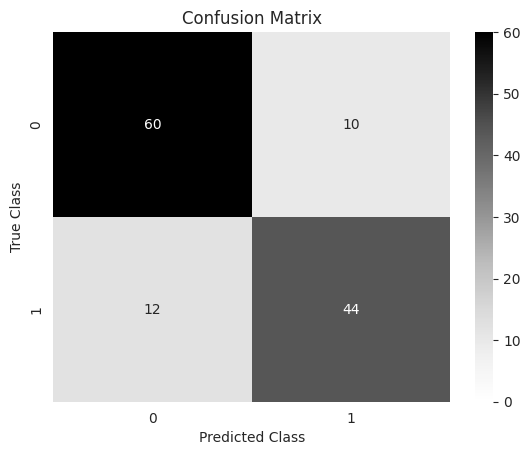

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test,pred_knn)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='Greys')
plt.title('Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.78571429 0.85714286]
Specificity Mean: 0.8214285714285714

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.85714286 0.78571429]
Recall/Sensitivity Mean: 0.8214285714285714

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.83333333 0.81481481]
Precision Mean: 0.8240740740740741

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.21428571 0.14285714]
False Positive Rate Mean: 0.17857142857142855

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.14285714 0.21428571]
False Negative Rate Mean: 0.17857142857142855

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.16666667 0.18518519]
False Discovery Rate Mean: 0.17592592592592593


### ROC Plot

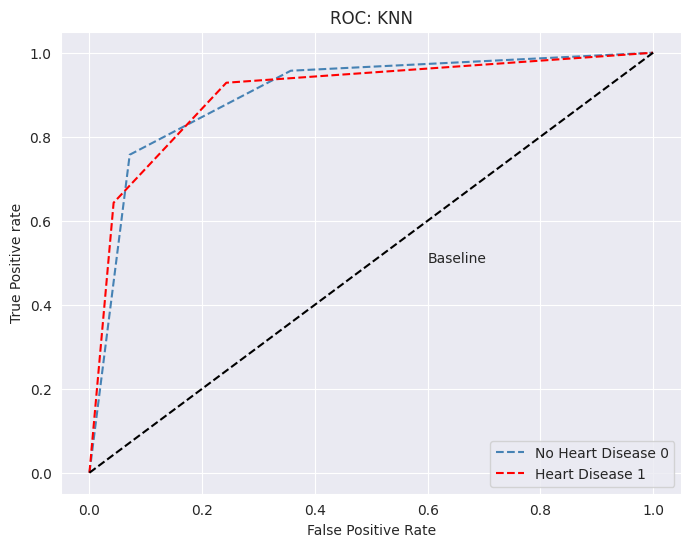

In [ ]:
#ROC Plot
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = knn.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: KNN')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('KNN ROC',dpi=300);

### AUC Score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
knn_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('KNN AUC Score:',knn_auc_score)

KNN AUC Score: 0.901


## Predictions and Confidences
 ### Classes and Probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = knn.predict_proba(X_test)
prediction_cplx = knn.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])

#pred_list = pd.concat(['frame','target_rs'],axis= 1)


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df.head()

,No heart disease,Heart disease,Predicted class
0,0.667,0.333,0
1,1.000,0.000,0
2,0.333,0.667,1
3,0.000,1.000,1
4,1.000,0.000,0


### Index of  incorrect predictions

In [ ]:
# Incorrect predictions

incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,   9,  10,  14,  15,  16,  20,  28,  32,  35,  38,  43,  44,
         53,  56,  59,  74,  78, 110, 111, 115, 122]),)

### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class

jaccard = jaccard_score(y_test, prediction_cplx, average = None)#prediction_probability

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.731707
1,0.666667


## Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

### Using model error

In [ ]:
# 95% confidence interval
# Calculated radius of the confidence interval using model error

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.16 * (1 - .16)) / 119)
print('Classification error interval: %.3f' % interval)

Classification error interval: 0.066


* The classification error of the model is 16% +/- 7%
* The true classification error of the model on unseen data is likely between 9% and 23%.

 **The true model skill may lie outside of this range.**

### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy

# 218 correct predictions of 238 instances and with 95% confidence interval,
# (provided to the function as a significance of 0.05)

lower, upper = proportion_confint(100, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.775 
Upper Bounds of Accuracy:0.906 


 **The true classification accuracy of the model on unseen data is likely between 78% and 91%**.

 **True model skill may lie outside of this range.**

# Stacking the Models

In [ ]:
# Stacking classifier

base_models= [('lr',lr),
              ('dt',dt),
              ('rf',rf),
              ('xgb',xgb),
              ('svm',svm),
              ('knn',knn)]

# Initialize Stacking Classifier with the Meta Learner

stack = StackingClassifier(estimators=base_models,
                           final_estimator= MLPClassifier(random_state=1, max_iter=200),cv=10)


# Train stacked model

stack.fit(X_train, y_train)

# Make predictions
stack_train_pred = stack.predict(X_train)
stack_test_pred = stack.predict(X_test)

# Training set model performance
stack_train_accuracy = accuracy_score(y_train, stack_train_pred) # Calculate Accuracy
stack_train_mcc = matthews_corrcoef(y_train, stack_train_pred) # Calculate MCC
stack_train_f1 = f1_score(y_train, stack_train_pred, average='weighted') # Calculate F1-score

# Test set model performance
stack_test_accuracy = accuracy_score(y_test, stack_test_pred) # Calculate Accuracy
stack_test_mcc = matthews_corrcoef(y_test, stack_test_pred) # Calculate MCC
stack_test_f1 = f1_score(y_test, stack_test_pred, average='weighted') # Calculate F1-score


print()
print('Model performance for Training set')
print()
print('- Accuracy: %s' % stack_train_accuracy)
print('- MCC: %s' % stack_train_mcc)
print('- F1 score: %s' % stack_train_f1)
print()
print('----------------------------------')
print()
print('Model performance for Test set')
print()
print('- Accuracy: %s' % stack_test_accuracy)
print('- MCC: %s' % stack_test_mcc)
print('- F1 score: %s' % stack_test_f1)

print()
print('Stack Model Parameters')
stack.get_params()


Model performance for Training set

- Accuracy: 0.9973498233215548
- MCC: 0.9947124670321424
- F1 score: 0.9973497178221261

----------------------------------

Model performance for Test set

- Accuracy: 0.9285714285714286
- MCC: 0.8552092390225933
- F1 score: 0.9285029710561625

Stack Model Parameters


{'cv': 10,
 'estimators': [('lr',
   LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42)),
  ('dt', DecisionTreeClassifier(max_depth=6, random_state=42)),
  ('rf',
   RandomForestClassifier(criterion='entropy', n_estimators=10, n_jobs=-1,
                          random_state=42)),
  ('xgb',
   XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
                 colsample_bylevel=None, colsample_bynode=None,
                 colsample_bytree=None, device=None, early_stopping_rounds=None,
                 enable_categorical=True, eval_metric=['logloss', 'error'],
                 feature_types=None, feature_weights=None, gamma=0.6,
                 grow_policy=None, importance_type=None,
                 interaction_constraints=None, learning_rate=None, max_bin=None,
                 max_cat_threshold=None, max_cat_to_onehot=None,
                 max_delta_step=None, max_depth=10, max_leaves=None,
                 min_child_weight=None, missing=nan, monotone_con

### Classification report

In [ ]:
# Classification report
print("stacked:",classification_report(y_test, stack_test_pred))

stacked:               precision    recall  f1-score   support

           0       0.93      0.94      0.94        70
           1       0.93      0.91      0.92        56

    accuracy                           0.93       126
   macro avg       0.93      0.93      0.93       126
weighted avg       0.93      0.93      0.93       126



### Confusion matrix

Text(0.5, 23.52222222222222, 'Predicted Class')

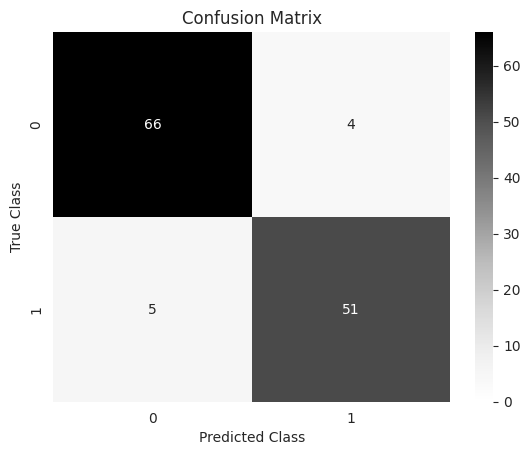

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test,stack_test_pred)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='Greys')
plt.title('Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance Metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.91071429 0.94285714]
Specificity Mean: 0.9267857142857143

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.94285714 0.91071429]
Recall/Sensitivity Mean: 0.9267857142857143

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.92957746 0.92727273]
Precision Mean: 0.9284250960307299

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.08928571 0.05714286]
False Positive Rate Mean: 0.07321428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.05714286 0.08928571]
False Negative Rate Mean: 0.07321428571428572

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.07042254 0.07272727]
False Discovery Rate Mean: 0.07157490396927016


### ROC plot

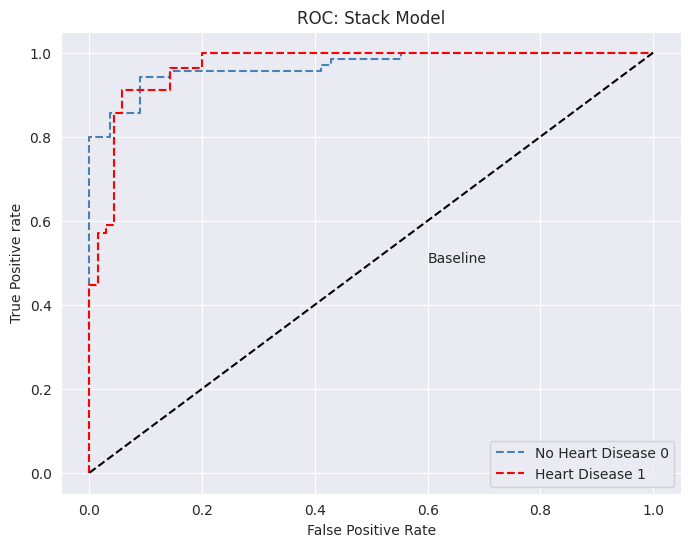

In [ ]:
#ROC Plot
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = stack.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: Stack Model')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('ROC',dpi=300);

### AUC SCORE

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
stack_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('Stack AUC Score:',stack_auc_score)

Stack AUC Score: 0.9684


## Predictions and Confidences
 ### Classes and Probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = stack.predict_proba(X_test)
prediction_cplx = stack.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])

#pred_list = pd.concat(['frame','target_rs'],axis= 1)


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df.head()

,No heart disease,Heart disease,Predicted class
0,0.983,0.017,0
1,0.981,0.019,0
2,0.308,0.692,1
3,0.032,0.968,1
4,0.986,0.014,0


### Index of  incorrect predictions

In [ ]:
# Incorrect predictions

incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,  15,  43,  56,  59,  65,  74, 111, 115]),)

### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class

jaccard = jaccard_score(y_test, prediction_cplx, average = None)#prediction_probability

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.88
1,0.85


## Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

### Using model error

In [ ]:
# 95% confidence interval
# Calculated radius of the confidence interval using model error

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.04 * (1 - .04)) / 119)
print('Classification error interval: %.3f' % interval)

Classification error interval: 0.035


* The classification error of the model is 4% +/- 4%
* The true classification error of the model on unseen data is likely between 0% (0.005) and 8%.

 **The true model skill may lie outside of this range.**

### Upper and lower bounds of model classification accuracy

In [ ]:
# Upper and lower bounds of model accuracy

# 218 correct predictions of 238 instances and with 95% confidence interval,
# (provided to the function as a significance of 0.05)

lower, upper = proportion_confint(114, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.922 
Upper Bounds of Accuracy:0.994 


 **The true classification accuracy of the model on unseen data is likely between 92% and 99%**.

 **True model skill may lie outside of this range.**

# All Models Train and Test Results

In [ ]:
# Train set results lists

acc_train_list = {'knn':knn_acc_train,
'svm': svm_acc_train,
'dt': dt_acc_train,
'rf': rf_acc_train,
'lr': lr_acc_train,
'xgb': xgb_acc_train,
'stack': stack_train_accuracy}

mcc_train_list = {'knn':knn_mcc_train,
'svm': svm_mcc_train,
'dt': dt_mcc_train,
'rf': rf_mcc_train,
'lr': lr_mcc_train,
'xgb': xgb_mcc_train,
'stack': stack_train_mcc}

f1_train_list = {'knn':knn_f1_train,
'svm': svm_f1_train,
'dt': dt_f1_train,
'rf': rf_f1_train,
'lr': lr_f1_train,
'xgb': xgb_f1_train,
'stack': stack_train_f1}

# Test results lists

acc_test_list = {'knn':knn_acc_test,
'svm': svm_acc_test,
'dt': dt_acc_test,
'rf': rf_acc_test,
'lr': lr_acc_test,
'xgb': xgb_acc_test,
'stack': stack_test_accuracy}

mcc_test_list = {'knn':knn_mcc_test,
'svm': svm_mcc_test,
'dt': dt_mcc_test,
'rf': rf_mcc_test,
'lr': lr_mcc_test,
'xgb': xgb_mcc_test,
'stack': stack_test_mcc}

f1_test_list = {'knn':knn_f1_test,
'svm': svm_f1_test,
'dt': dt_f1_test,
'rf': rf_f1_test,
'lr': lr_f1_test,
'xgb': xgb_f1_test,
'stack': stack_test_f1}

auc_list = {'knn':knn_auc_score,
'svm':svm_auc_score,
'dt':dt_auc_score,
'rf':rf_auc_score,
'lr':lr_auc_score,
'xgb':xgb_auc_score,
'stack':stack_auc_score}


# All Models Training Results

In [ ]:
# Training results dataframe

acc_df = pd.DataFrame.from_dict(acc_train_list, orient='index', columns=['Accuracy'])
mcc_df = pd.DataFrame.from_dict(mcc_train_list, orient='index', columns=['MCC'])
f1_df = pd.DataFrame.from_dict(f1_train_list, orient='index', columns=['F1'])

print('All Models Training Results')

train_results_df = pd.concat([acc_df, mcc_df,f1_df], axis=1)
train_results_df



All Models Training Results


,Accuracy,MCC,F1
knn,0.945230,0.890455,0.945216
svm,0.899293,0.799286,0.899167
dt,0.901943,0.806147,0.901888
rf,0.995583,0.991178,0.995582
lr,0.853357,0.707250,0.853174
xgb,0.992049,0.984169,0.992047
stack,0.997350,0.994712,0.997350


# All Models Test Results

In [ ]:
# Test results dataframe

test_acc_df = pd.DataFrame.from_dict(acc_test_list, orient='index', columns=['Accuracy'])
test_mcc_df = pd.DataFrame.from_dict(mcc_test_list, orient='index', columns=['MCC'])
test_f1_df = pd.DataFrame.from_dict(f1_test_list, orient='index', columns=['F1'])
auc_df = pd.DataFrame.from_dict(auc_list, orient='index',columns=['AUC'])

print('All Models Test Results')


test_results_df = pd.concat([test_acc_df, test_mcc_df, test_f1_df,auc_df], axis=1)
test_results_df

All Models Test Results


,Accuracy,MCC,F1,AUC
knn,0.825397,0.645497,0.822535,0.901000
svm,0.857143,0.712109,0.855835,0.901300
dt,0.849206,0.695304,0.844898,0.904200
rf,0.896825,0.790876,0.894912,0.966709
lr,0.849206,0.699568,0.848433,0.913300
xgb,0.920635,0.839286,0.919643,0.959439
stack,0.928571,0.855209,0.928503,0.968400


*_____*

## Stacking the Best Performers

In [ ]:
# Stacking classifier of the best performing models: random forest and xgboost

base_models= [('rf',rf),
              ('xgb',xgb)]

# Initialize Stacking Classifier with the Meta Learner

stack = StackingClassifier(estimators=base_models,
                           final_estimator= MLPClassifier(random_state=1, max_iter=200),cv=10)


# Train stacked model

stack.fit(X_train, y_train)

# Make predictions
stack_train_pred = stack.predict(X_train)
stack_test_pred = stack.predict(X_test)

# Training set model performance
stack_train_accuracy = accuracy_score(y_train, stack_train_pred) # Calculate Accuracy
stack_train_mcc = matthews_corrcoef(y_train, stack_train_pred) # Calculate MCC
stack_train_f1 = f1_score(y_train, stack_train_pred, average='weighted') # Calculate F1-score

# Test set model performance
stack_test_accuracy = accuracy_score(y_test, stack_test_pred) # Calculate Accuracy
stack_test_mcc = matthews_corrcoef(y_test, stack_test_pred) # Calculate MCC
stack_test_f1 = f1_score(y_test, stack_test_pred, average='weighted') # Calculate F1-score


print()
print('Model performance for Training set')
print()
print('- Accuracy: %s' % stack_train_accuracy)
print('- MCC: %s' % stack_train_mcc)
print('- F1 score: %s' % stack_train_f1)
print()
print('----------------------------------')
print()
print('Model performance for Test set')
print()
print('- Accuracy: %s' % stack_test_accuracy)
print('- MCC: %s' % stack_test_mcc)
print('- F1 score: %s' % stack_test_f1)

print()
print('Stack Model Parameters')
stack.get_params()


Model performance for Training set

- Accuracy: 0.9973498233215548
- MCC: 0.9947124670321424
- F1 score: 0.9973497178221261

----------------------------------

Model performance for Test set

- Accuracy: 0.9126984126984127
- MCC: 0.8230047070091903
- F1 score: 0.9126147424019765

Stack Model Parameters


{'cv': 10,
 'estimators': [('rf',
   RandomForestClassifier(criterion='entropy', n_estimators=10, n_jobs=-1,
                          random_state=42)),
  ('xgb',
   XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
                 colsample_bylevel=None, colsample_bynode=None,
                 colsample_bytree=None, device=None, early_stopping_rounds=None,
                 enable_categorical=True, eval_metric=['logloss', 'error'],
                 feature_types=None, feature_weights=None, gamma=0.6,
                 grow_policy=None, importance_type=None,
                 interaction_constraints=None, learning_rate=None, max_bin=None,
                 max_cat_threshold=None, max_cat_to_onehot=None,
                 max_delta_step=None, max_depth=10, max_leaves=None,
                 min_child_weight=None, missing=nan, monotone_constraints=None,
                 multi_strategy=None, n_estimators=None, n_jobs=-1,
                 num_parallel_tree=None, ...))],
 'final_

### Classification report

In [ ]:
# Classification report
print("stacked best performers:",classification_report(y_test, stack_test_pred))

stacked best performers:               precision    recall  f1-score   support

           0       0.92      0.93      0.92        70
           1       0.91      0.89      0.90        56

    accuracy                           0.91       126
   macro avg       0.91      0.91      0.91       126
weighted avg       0.91      0.91      0.91       126



### Confusion matrix

Text(0.5, 23.52222222222222, 'Predicted Class')

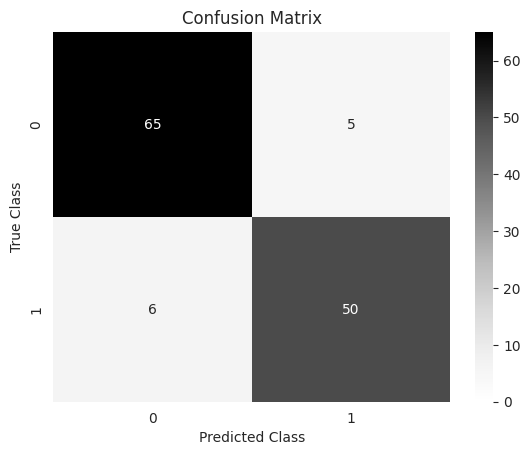

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test,stack_test_pred)
#sns.heatmap(cm, annot=True)
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cbar=True, cmap='Greys')
plt.title('Confusion Matrix')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')

### Performance metrics

In [ ]:
#Performance metrics from confusion matrix

FP = cm.sum(axis=0) - np.diag(cm)
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
TN = cm.sum() - (FP + FN + TP)

FP = FP.astype(float)
FN = FN.astype(float)
TP = TP.astype(float)
TN = TN.astype(float)

# Sensitivity, hit rate, Recall, or true positive rate
TPR = TP/(TP+FN)

# Specificity or true negative rate
TNR = TN/(TN+FP)

# Precision or positive predictive value
PPV = TP/(TP+FP)

# Negative predictive value
NPV = TN/(TN+FN)

# Fall out or false positive rate
FPR = FP/(FP+TN)

# False negative rate
FNR = FN/(TP+FN)

# False discovery rate
FDR = FP/(TP+FP)


print('Class:',class_label)

print('Specificity:',TNR)
print('Specificity Mean:',TNR.mean())

print()

print('Class:',class_label)

print('Recall/Sensitivity:',TPR)
print('Recall/Sensitivity Mean:',TPR.mean())

print()

print('Class:',class_label)

print('Precision:',PPV)
print('Precision Mean:',PPV.mean())

print()

print('Class:',class_label)

print('False Positive Rate:',FPR)
print('False Positive Rate Mean:',FPR.mean())

print()

print('Class:',class_label)

print('False Negative Rate:',FNR)
print('False Negative Rate Mean:',FNR.mean())

print()

print('Class:',class_label)

print('False Discovery Rate:',FDR)
print('False Discovery Rate Mean:',FDR.mean())

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Specificity: [0.89285714 0.92857143]
Specificity Mean: 0.9107142857142858

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Recall/Sensitivity: [0.92857143 0.89285714]
Recall/Sensitivity Mean: 0.9107142857142858

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
Precision: [0.91549296 0.90909091]
Precision Mean: 0.912291933418694

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Positive Rate: [0.10714286 0.07142857]
False Positive Rate Mean: 0.08928571428571427

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Negative Rate: [0.07142857 0.10714286]
False Negative Rate Mean: 0.08928571428571427

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}
False Discovery Rate: [0.08450704 0.09090909]
False Discovery Rate Mean: 0.08770806658130602


### ROC plot

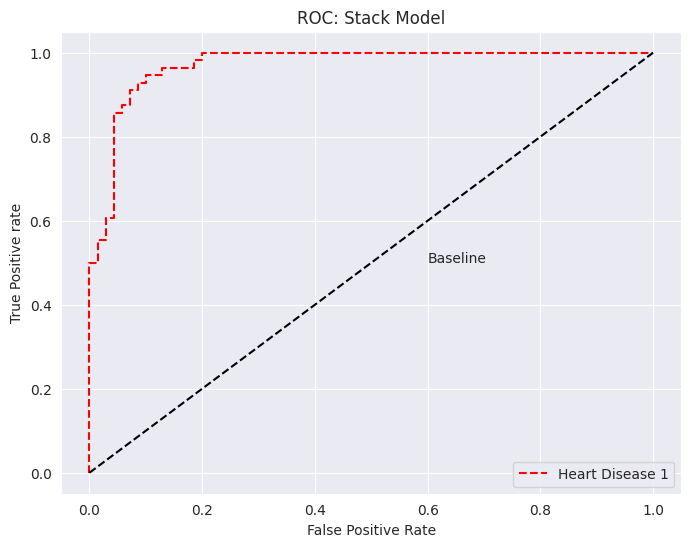

In [ ]:
#ROC Plot
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

prediction_cplx = stack.predict_proba(X_test)

# roc curve for classes
fpr = {}
tpr = {}
thresh ={}

n_class = 2

for i in range(n_class):
    fpr[i], tpr[i], thresh[i] = roc_curve(y_test, prediction_cplx[:,i], pos_label=i)

#y_score = classifier.fit(X_train, y_train).decision_function(X_test)
# Compute micro-average ROC curve and ROC area
#fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
#roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])




# plotting
plt.figure(figsize=(8, 6))
#plt.plot(fpr[0], tpr[0], linestyle='--',color='steelblue', label='No Heart Disease 0')
plt.plot(fpr[1], tpr[1], linestyle='--',color='red', label='Heart Disease 1')
plt.plot([0,1],[0,1],color="black",linestyle="--")
#plt.plot(fpr[2], tpr[2], linestyle='--',color='blue', label='Class 2 vs Rest')
#plt.plot(fpr[3], tpr[3], linestyle='--',color='red', label='Class 3 vs Rest')
#plt.plot(fpr[4], tpr[4], linestyle='--',color='black', label='Class 4 vs Rest')
#plt.plot(fpr[5], tpr[5], linestyle='--',color='purple', label='Class 5 vs Rest')
#plt.plot(fpr[6], tpr[6], linestyle='--',color='yellow', label='Class 6 vs Rest')
plt.title('ROC: Stack Model')
plt.text(0.6,0.5,"Baseline")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
#plt.savefig('ROC',dpi=300);

### AUC score

In [ ]:
# AUC score

#from sklearn.metrics import roc_auc_score
stack_auc_score = roc_auc_score(y_test, prediction_cplx[:,i]).round(4)

print('Stack AUC Score:',stack_auc_score)

Stack AUC Score: 0.9709


## Predictions and Confidences
 ### Classes and Probabilities

In [ ]:
# Classes and Probabilities

prediction_probability = stack.predict_proba(X_test)
prediction_cplx = stack.predict(X_test)

class_df = pd.DataFrame(prediction_cplx.round(3),columns=['Predicted class'])
proba_df = pd.DataFrame(prediction_probability.round(3),columns=['No heart disease','Heart disease'])

#pred_list = pd.concat(['frame','target_rs'],axis= 1)


predictions_df = pd.concat([proba_df,class_df ], axis=1)
predictions_df.head()

,No heart disease,Heart disease,Predicted class
0,0.985,0.015,0
1,0.974,0.026,0
2,0.297,0.703,1
3,0.037,0.963,1
4,0.982,0.018,0


### Index of incorrect predictions

In [ ]:
# Incorrect predictions
#np.where
incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,  15,  36,  43,  56,  59,  61,  65,  74, 111, 115]),)

### Jaccard similarity coefficient

In [ ]:
# Jaccard similarity coefficient
# Predicted class compared with actual class

jaccard = jaccard_score(y_test, prediction_cplx, average = None)#prediction_probability

jaccard_df = pd.DataFrame(jaccard,columns=['Jaccard score'])
jaccard_df

,Jaccard score
0,0.855263
1,0.819672


## Confidence interval

The confidence interval is a likelihood over a range. The true model skill may lie outside of this range.

**Commonly used number of standard deviations from the Gaussian distribution and their corresponding significance level are as follows:**

* 1.64 (90%)
* 1.96 (95%)
* 2.33 (98%)
* 2.58 (99%)

### Using model error

In [ ]:
# 95% confidence interval
# Calculated radius of the confidence interval using model error

# where: interval = z * sqrt( (error * (1 - error)) / n)

interval = 1.96 * sqrt( (0.04 * (1 - .04)) / 119)
print('Classification error interval: %.3f' % interval)

Classification error interval: 0.035


**The classification error of the model is 4% +/- 4%**

**The true classification error of the model on unseen data is likely between 0% and 8%.**

**The true model skill may lie outside of this range.**

### Upper and lower bounds of model accuracy

In [ ]:
# Upper and lower bounds of model accuracy

# 218 correct predictions of 238 instances and with 95% confidence interval,
# (provided to the function as a significance of 0.05)

lower, upper = proportion_confint(114, 119, 0.05)

print('Lower Bounds of Accuracy:%.3f ' % lower)
print('Upper Bounds of Accuracy:%.3f ' %upper)

Lower Bounds of Accuracy:0.922 
Upper Bounds of Accuracy:0.994 


 **The true classification accuracy of the model on unseen data is likely between 92% and 99%**.

 **True model skill may lie outside of this range.**

**________________**

# Save the best model
#### Joblib

In [ ]:
# Best performer: XGBoost classifier

joblib.dump(xgb,'./Heart_Dis_XGB_best_119_19.joblib')

['./Heart_Dis_XGB_best_119_19.joblib']

### Test saved model

In [ ]:
# Sanity Check
# Load the model
XGB=joblib.load('./Heart_Dis_XGB_best_119_19.joblib')

# Make a prediction
print('Class:',class_label)
print()
print('The class probabilites are:', XGB.predict_proba(X_test[0:1]))
print()
print('The sample prediction is class:',XGB.predict(X_test[0:1]))
print()
predictions_df.head()

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}

The class probabilites are: [[0.9889759 0.0110241]]

The sample prediction is class: [0]



,No heart disease,Heart disease,Predicted class
0,0.985,0.015,0
1,0.974,0.026,0
2,0.297,0.703,1
3,0.037,0.963,1
4,0.982,0.018,0


In [ ]:
# Incorrect predictions

#prediction_probability = xgb.predict_proba(X_test)
prediction_cplx = XGB.predict(X_test)

incorrects = np.where(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,  15,  36,  43,  56,  59,  61,  65,  74, 111]),)

**________________________________________**

### Save the best model
#### Pickle

In [ ]:
# Best performer, stacked random forest and xgboost models

filename = 'Heart_Dis_XGB.pkl'
pickle.dump(xgb, open(filename,'wb'))

### Test saved model

In [ ]:
# Sanity Check
# Load model
Hrt_prd = pickle.load(open(filename,'rb'))

# Make a prediction
print('Class:',class_label)
print()
print('The class probabilites are:', Hrt_prd.predict_proba(X_test[2:3]).round(3))
print()
print('The sample prediction is class:', Hrt_prd.predict(X_test[2:3]))
predictions_df.head()

Class: {0: 'No Heart Disease', 1: 'Heart Disease'}

The class probabilites are: [[0.235 0.765]]

The sample prediction is class: [1]


,No heart disease,Heart disease,Predicted class
0,0.985,0.015,0
1,0.974,0.026,0
2,0.297,0.703,1
3,0.037,0.963,1
4,0.982,0.018,0


In [ ]:
# Incorrect predictions

#incorrects = np.where(prediction_cplx.reshape((-1,)) != y_test)
#or, incorrects = np.asarray(prediction_cplx.reshape((-1,)) != y_test).nonzero()
#or, incorrects = np.nonzero(prediction_cplx.reshape((-1,)) != y_test) ##old method##

prediction_cplx = Hrt_prd.predict(X_test)

incorrects = np.where(prediction_cplx.reshape((-1,)) != y_test)
incorrects

(array([  5,  15,  36,  43,  56,  59,  61,  65,  74, 111]),)


# DS 340W — Expanded Heart Disease Dataset + Parent-Paper Methods

This notebook uses the **expanded 1,190-row Comprehensive Heart Disease dataset** and adds the named methods from the three parent papers.

It covers:
- Parent 1: preprocessing, GA + RFEM, scaling, cluster/under/over-sampling, SMOTE, SVM, PCA, LDA, NB, DT, RF, MLDCNN, AEHOM-style optimization, k-fold evaluation, and a bee-style optimization experiment.
- Parent 2: KNN, RF, DT, SVM, Gaussian NB, AdaBoost, selective duplication of misclassified cases, bagging, leave-one-out / 5-fold / 10-fold evaluation.
- Parent 3: EG-HFS (entropy/gain/symmetric-uncertainty feature selection), LR, RF, SVM, DT, SGD, Gradient Boosting, XGBoost.

**Important:** the first parent paper names custom procedures but does not provide enough source detail to reproduce every custom step byte-for-byte. The code below implements the published steps as closely as possible and labels implementation choices.


In [ ]:

!pip -q install imbalanced-learn xgboost tensorflow

import warnings, math, random
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

from sklearn.model_selection import train_test_split, StratifiedKFold, LeaveOneOut, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report, mutual_info_score
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import ClusterCentroids

from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(SEED)

print("Imports complete.")


Imports complete.


## 1. Load expanded dataset

In [ ]:

DATA_PATH = "/content/heart_statlog_cleveland_hungary_final.csv"
data = pd.read_csv(DATA_PATH)
print("Shape:", data.shape)
display(data.head())
print(data["target"].value_counts())


Shape: (1190, 12)


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


target
1    629
0    561
Name: count, dtype: int64


## 2. Preprocessing + 80/10/10 split

In [ ]:

data_full = data.copy()
data_unique = data.drop_duplicates().reset_index(drop=True)

print("Full rows:", len(data_full))
print("Unique rows:", len(data_unique))
print("Duplicates:", len(data_full)-len(data_unique))

# Professor asked for expanded dataset. Keep 1190 rows by default.
USE_UNIQUE = False
work = data_unique.copy() if USE_UNIQUE else data_full.copy()

for c in work.columns:
    if work[c].isna().any():
        work[c] = work[c].fillna(work[c].median())

X_raw = work.drop(columns=["target"])
y = work["target"].astype(int)

X_train_raw, X_tmp_raw, y_train, y_tmp = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_tmp_raw, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED
)

print("Train:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test:", X_test_raw.shape)


Full rows: 1190
Unique rows: 918
Duplicates: 272
Train: (952, 11)
Validation: (119, 11)
Test: (119, 11)


## 3. Parent 3 — EG-HFS

In [ ]:

def entropy_discrete(v):
    vals, counts = np.unique(v, return_counts=True)
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p + 1e-12))

def symmetric_uncertainty(x, y, n_bins=8):
    x = np.asarray(x).reshape(-1, 1)
    if len(np.unique(x)) > n_bins:
        kb = KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy="quantile")
        xd = kb.fit_transform(x).ravel().astype(int)
    else:
        xd = x.ravel()
    yd = np.asarray(y).ravel()
    hx, hy = entropy_discrete(xd), entropy_discrete(yd)
    gain = mutual_info_score(xd, yd)
    return 0.0 if (hx+hy)==0 else 2.0*gain/(hx+hy)

eg_scores = pd.Series({c:symmetric_uncertainty(X_train_raw[c], y_train) for c in X_train_raw.columns}).sort_values(ascending=False)

# Paper gives the SU formula but not a numeric cutoff.
EG_THRESHOLD = eg_scores.median()
eg_features = eg_scores[eg_scores >= EG_THRESHOLD].index.tolist()

display(eg_scores.to_frame("SU score"))
print("EG-HFS selected:", eg_features)


,SU score
ST slope,0.144070
exercise angina,0.126039
chest pain type,0.111762
oldpeak,0.064273
sex,0.055488
max heart rate,0.043135
fasting blood sugar,0.030281
age,0.024784
cholesterol,0.014344
resting bp s,0.006944


EG-HFS selected: ['ST slope', 'exercise angina', 'chest pain type', 'oldpeak', 'sex', 'max heart rate']


## 4. Parent 1 — Genetic Algorithm

In [ ]:
# =========================================================
# Parent 1 — Genetic Algorithm Feature Selection
# =========================================================

# Paper-stated GA settings:
# 18 generations, 80 genomes, 40 best retained,
# crossover = 5%, mutation = 5%

PAPER_MODE = True

GA_GENERATIONS = 18 if PAPER_MODE else 5
GA_POPULATION = 80 if PAPER_MODE else 24
GA_ELITE = 40 if PAPER_MODE else 8
GA_MUTATION_RATE = 0.05
GA_CROSSOVER_RATE = 0.05

cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# Clear cache whenever this cell is rerun
fitness_cache = {}


def ga_fitness(mask):

    # IMPORTANT:
    # convert 0/1 genome into an actual Boolean mask
    mask_bool = np.asarray(mask, dtype=bool)

    key = tuple(mask_bool.astype(int))

    if key in fitness_cache:
        return fitness_cache[key]

    if mask_bool.sum() == 0:
        return 0.0

    # Select each feature only once
    cols = X_train_raw.columns[mask_bool].tolist()

    model = Pipeline([
        ("scaler", StandardScaler()),
        (
            "lr",
            LogisticRegression(
                max_iter=1000,
                random_state=SEED
            )
        )
    ])

    score = cross_val_score(
        model,
        X_train_raw[cols],
        y_train,
        cv=cv3,
        scoring="accuracy",
        n_jobs=-1
    ).mean()

    fitness_cache[key] = score

    return score


def run_ga():

    n_features = X_train_raw.shape[1]

    # Each genome contains one bit per dataset feature
    population = np.random.randint(
        0,
        2,
        size=(GA_POPULATION, n_features),
        dtype=np.int8
    )

    # Make sure no genome has zero selected features
    for i in range(len(population)):
        if population[i].sum() == 0:
            population[
                i,
                np.random.randint(n_features)
            ] = 1

    history = []

    global_best = None
    global_best_score = -np.inf

    for gen in range(GA_GENERATIONS):

        scores = np.array([
            ga_fitness(ind)
            for ind in population
        ])

        # Sort best to worst
        order = np.argsort(scores)[::-1]

        population = population[order]
        scores = scores[order]

        # Preserve global best
        if scores[0] > global_best_score:
            global_best_score = scores[0]
            global_best = population[0].copy()

        history.append(global_best_score)

        elite_n = min(
            GA_ELITE,
            len(population)
        )

        elites = population[:elite_n].copy()

        new_population = [
            e.copy()
            for e in elites
        ]

        while len(new_population) < GA_POPULATION:

            p1 = elites[
                np.random.randint(elite_n)
            ].copy()

            p2 = elites[
                np.random.randint(elite_n)
            ].copy()

            child = p1.copy()

            # Crossover
            if (
                np.random.rand() < GA_CROSSOVER_RATE
                and n_features > 1
            ):
                point = np.random.randint(
                    1,
                    n_features
                )

                child = np.concatenate([
                    p1[:point],
                    p2[point:]
                ]).astype(np.int8)

            # Mutation
            mutation_mask = (
                np.random.rand(n_features)
                < GA_MUTATION_RATE
            )

            child[mutation_mask] = (
                1 - child[mutation_mask]
            )

            # Never allow zero selected features
            if child.sum() == 0:
                child[
                    np.random.randint(n_features)
                ] = 1

            new_population.append(
                child.astype(np.int8)
            )

        population = np.array(
            new_population[:GA_POPULATION],
            dtype=np.int8
        )

        best_features_now = (
            X_train_raw.columns[
                global_best.astype(bool)
            ].tolist()
        )

        print(
            f"Gen {gen + 1}/{GA_GENERATIONS}: "
            f"best={global_best_score:.4f}, "
            f"features={len(best_features_now)}"
        )

    # Final feature list
    best_bool = global_best.astype(bool)

    ga_features = (
        X_train_raw.columns[
            best_bool
        ].tolist()
    )

    return ga_features, history


ga_features, ga_history = run_ga()

print("\nGA features:", ga_features)
print("Number selected:", len(ga_features))

# Safety check
assert len(ga_features) == len(set(ga_features)), \
    "GA produced duplicate features."

Gen 1/18: best=0.8393, features=8
Gen 2/18: best=0.8393, features=8
Gen 3/18: best=0.8393, features=8
Gen 4/18: best=0.8393, features=8
Gen 5/18: best=0.8393, features=8
Gen 6/18: best=0.8393, features=6
Gen 7/18: best=0.8393, features=6
Gen 8/18: best=0.8393, features=6
Gen 9/18: best=0.8393, features=6
Gen 10/18: best=0.8393, features=6
Gen 11/18: best=0.8393, features=6
Gen 12/18: best=0.8393, features=6
Gen 13/18: best=0.8393, features=9
Gen 14/18: best=0.8393, features=9
Gen 15/18: best=0.8393, features=9
Gen 16/18: best=0.8393, features=9
Gen 17/18: best=0.8393, features=9
Gen 18/18: best=0.8393, features=9

GA features: ['sex', 'chest pain type', 'resting bp s', 'cholesterol', 'resting ecg', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope']
Number selected: 9


## 5. Parent 1 — RFEM / RFE

In [ ]:
# =========================================================
# Parent 1 — RFEM / RFE
# =========================================================

# Paper does not specify the exact RFE estimator
# or final feature count.
# Implementation choice:
# Random Forest estimator and retain about 70%
# of the GA-selected features.

# Remove duplicates as an extra safety check
ga_features_safe = list(dict.fromkeys(ga_features))

# If GA somehow returns fewer than 2 features,
# fall back to all features
if len(ga_features_safe) < 2:
    ga_features_safe = X_train_raw.columns.tolist()

n_keep = max(
    2,
    int(
        math.ceil(
            len(ga_features_safe) * 0.70
        )
    )
)

# Cannot select more features than exist
n_keep = min(
    n_keep,
    len(ga_features_safe)
)

rfe_estimator = RandomForestClassifier(
    n_estimators=200,
    random_state=SEED,
    n_jobs=-1
)

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=n_keep,
    step=1
)

rfe.fit(
    X_train_raw[ga_features_safe],
    y_train
)

p1_features = [
    feature
    for feature, keep
    in zip(
        ga_features_safe,
        rfe.support_
    )
    if keep
]

print("GA features:", ga_features_safe)
print("GA + RFEM selected:", p1_features)

# Safety checks
assert len(p1_features) == len(set(p1_features))
assert len(p1_features) >= 2

GA features: ['sex', 'chest pain type', 'resting bp s', 'cholesterol', 'resting ecg', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope']
GA + RFEM selected: ['chest pain type', 'resting bp s', 'cholesterol', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope']


## 6. Parent 1 — scaling + cluster/under/over-sampling + SMOTE

In [ ]:

scaler_p1 = StandardScaler()
Xtr_p1 = scaler_p1.fit_transform(X_train_raw[p1_features])
Xva_p1 = scaler_p1.transform(X_val_raw[p1_features])
Xte_p1 = scaler_p1.transform(X_test_raw[p1_features])

# Operationalization of the paper's UCOM/USCOM-like balancing:
# cluster-centroid under-sampling followed by SMOTE.
cc = ClusterCentroids(random_state=SEED)
X_cc, y_cc = cc.fit_resample(Xtr_p1, y_train)

smote = SMOTE(random_state=SEED)
X_p1_bal, y_p1_bal = smote.fit_resample(X_cc, y_cc)

print("Original train:", pd.Series(y_train).value_counts().to_dict())
print("After cluster under-sampling:", pd.Series(y_cc).value_counts().to_dict())
print("After SMOTE:", pd.Series(y_p1_bal).value_counts().to_dict())


Original train: {1: 503, 0: 449}
After cluster under-sampling: {0: 449, 1: 449}
After SMOTE: {0: 449, 1: 449}


## 7. Parent 1 conventional methods

In [ ]:

parent1_models = {
    "SVM": SVC(probability=True, random_state=SEED),
    "PCA + Logistic Regression": Pipeline([
        ("pca", PCA(n_components=min(5, X_p1_bal.shape[1]))),
        ("lr", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    "LDA": LinearDiscriminantAnalysis(),
    "Gaussian NB": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}

def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr,ytr)
    pred = model.predict(Xte)
    if hasattr(model,"predict_proba"):
        prob = model.predict_proba(Xte)[:,1]
        aucv = roc_auc_score(yte,prob)
    elif hasattr(model,"decision_function"):
        prob = model.decision_function(Xte)
        aucv = roc_auc_score(yte,prob)
    else:
        aucv = np.nan
    cm = confusion_matrix(yte,pred)
    spec = cm[0,0]/max(1,cm[0].sum())
    return {
        "Model":name,
        "Accuracy":accuracy_score(yte,pred),
        "Precision":precision_score(yte,pred,zero_division=0),
        "Recall/TPR":recall_score(yte,pred,zero_division=0),
        "F1":f1_score(yte,pred,zero_division=0),
        "Specificity":spec,
        "AUC":aucv
    }, model

p1_results = []
for name,m in parent1_models.items():
    row,_ = evaluate(name,m,X_p1_bal,y_p1_bal,Xte_p1,y_test)
    p1_results.append(row)

display(pd.DataFrame(p1_results).sort_values("Accuracy",ascending=False))


,Model,Accuracy,Precision,Recall/TPR,F1,Specificity,AUC
5,Random Forest,0.932773,0.950820,0.920635,0.935484,0.946429,0.976757
4,Decision Tree,0.907563,0.906250,0.920635,0.913386,0.892857,0.906746
0,SVM,0.899160,0.892308,0.920635,0.906250,0.875000,0.930839
1,PCA + Logistic Regression,0.823529,0.850000,0.809524,0.829268,0.839286,0.893141
2,LDA,0.823529,0.850000,0.809524,0.829268,0.839286,0.894274
3,Gaussian NB,0.815126,0.836066,0.809524,0.822581,0.821429,0.906746


## 8. Parent 1 — MLDCNN

In [ ]:

@tf.keras.utils.register_keras_serializable()
def gaussian_activation(x):
    return tf.exp(-tf.square(x))

def make_mldcnn(n_features):
    model = keras.Sequential([
        layers.Input(shape=(n_features,1)),
        layers.Conv1D(32,3,padding="same"),
        layers.Activation(gaussian_activation),
        layers.BatchNormalization(),
        layers.Conv1D(64,3,padding="same"),
        layers.Activation(gaussian_activation),
        layers.BatchNormalization(),
        layers.Conv1D(64,3,padding="same"),
        layers.Activation(gaussian_activation),
        layers.Flatten(),
        layers.Dense(64),
        layers.Activation(gaussian_activation),
        layers.Dropout(0.20),
        layers.Dense(1,activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=["accuracy",keras.metrics.Precision(name="precision"),keras.metrics.Recall(name="recall")]
    )
    return model

X_p1_bal_cnn = np.asarray(X_p1_bal,dtype=np.float32)[...,None]
Xva_p1_cnn = np.asarray(Xva_p1,dtype=np.float32)[...,None]
Xte_p1_cnn = np.asarray(Xte_p1,dtype=np.float32)[...,None]

mldcnn = make_mldcnn(X_p1_bal_cnn.shape[1])
early = keras.callbacks.EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True)

mldcnn.fit(
    X_p1_bal_cnn,np.asarray(y_p1_bal),
    validation_data=(Xva_p1_cnn,np.asarray(y_val)),
    epochs=60,batch_size=32,callbacks=[early],verbose=1
)

mld_prob = mldcnn.predict(Xte_p1_cnn,verbose=0).ravel()
mld_pred = (mld_prob>=0.5).astype(int)

print(classification_report(y_test,mld_pred))
print("AUC:",roc_auc_score(y_test,mld_prob))


Epoch 1/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.6737 - loss: 0.6339 - precision: 0.6921 - recall: 0.6258 - val_accuracy: 0.5882 - val_loss: 0.6840 - val_precision: 0.5729 - val_recall: 0.8730
Epoch 2/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8051 - loss: 0.4330 - precision: 0.7991 - recall: 0.8151 - val_accuracy: 0.5966 - val_loss: 0.6735 - val_precision: 0.5773 - val_recall: 0.8889
Epoch 3/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8820 - loss: 0.3428 - precision: 0.8871 - recall: 0.8753 - val_accuracy: 0.7059 - val_loss: 0.6573 - val_precision: 0.7414 - val_recall: 0.6825
Epoch 4/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8976 - loss: 0.2906 - precision: 0.9048 - recall: 0.8886 - val_accuracy: 0.6218 - val_loss: 0.6424 - val_precision: 0.7647 - val_recall: 0.4127
Epoch 5/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9176 - loss: 0.2463 - precision: 0.9271 - recall: 0.9065 - val_accuracy: 0.6134 - val_loss: 0.6257 - v

## 9. Parent 1 — AEHOM-style direct weight optimization

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score

# ------------------------------------------------------------
# Flatten / unflatten neural-network weights
# ------------------------------------------------------------

def flatten_weights(weights):
    shapes = [w.shape for w in weights]
    sizes = [w.size for w in weights]

    flat = np.concatenate(
        [w.ravel() for w in weights]
    ).astype(np.float32)

    return flat, shapes, sizes


def unflatten_weights(flat, shapes, sizes):
    out = []
    i = 0

    for shape, size in zip(shapes, sizes):
        arr = flat[i:i + size].reshape(shape)
        out.append(arr.astype(np.float32))
        i += size

    return out


# ------------------------------------------------------------
# Starting MLDCNN weights
# ------------------------------------------------------------

base_flat, w_shapes, w_sizes = flatten_weights(
    mldcnn.get_weights()
)

# ------------------------------------------------------------
# AEHOM parameters
# ------------------------------------------------------------

N_CLANS = 3
ELEPHANTS_PER_CLAN = 4
AEHO_ITERS = 6

ALPHA = 0.5
BETA = 0.1

MUTATION_RATE = 0.01
PERTURB_SD = 0.01

np.random.seed(42)

POP_SIZE = N_CLANS * ELEPHANTS_PER_CLAN


# ------------------------------------------------------------
# Create initial elephant population
# ------------------------------------------------------------

population = np.stack([
    base_flat
    + np.random.normal(
        0,
        PERTURB_SD,
        size=base_flat.shape
    ).astype(np.float32)

    for _ in range(POP_SIZE)
])


# ------------------------------------------------------------
# Make a candidate numerically safe
# ------------------------------------------------------------

def sanitize_candidate(v):

    v = np.asarray(v, dtype=np.float32)

    # Replace invalid values
    v = np.nan_to_num(
        v,
        nan=0.0,
        posinf=5.0,
        neginf=-5.0
    )

    # Prevent extremely large neural-network weights
    v = np.clip(v, -5.0, 5.0)

    return v.astype(np.float32)


# ------------------------------------------------------------
# AEHOM fitness
# ------------------------------------------------------------

def aeho_fitness(v):

    try:

        v = sanitize_candidate(v)

        weights = unflatten_weights(
            v,
            w_shapes,
            w_sizes
        )

        mldcnn.set_weights(weights)

        result = mldcnn.evaluate(
            Xva_p1_cnn,
            np.asarray(y_val),
            verbose=0
        )

        # evaluate() may return [loss, metric1, ...]
        if isinstance(result, (list, tuple)):
            loss = float(result[0])
        else:
            loss = float(result)

        # Reject NaN / Inf fitness
        if not np.isfinite(loss):
            return np.inf

        return loss

    except Exception:
        return np.inf


# ------------------------------------------------------------
# Keep GLOBAL best solution
# ------------------------------------------------------------

global_best = base_flat.copy()

base_loss = aeho_fitness(global_best)

if np.isfinite(base_loss):
    global_best_loss = base_loss
else:
    global_best_loss = np.inf

print(
    f"Starting validation loss: "
    f"{global_best_loss:.5f}"
)


# ------------------------------------------------------------
# AEHOM optimization
# ------------------------------------------------------------

for it in range(AEHO_ITERS):

    # Evaluate current population
    scores = np.array(
        [aeho_fitness(v) for v in population],
        dtype=np.float64
    )

    # Replace invalid scores with infinity
    scores[~np.isfinite(scores)] = np.inf

    # Find best elephant in current iteration
    iteration_best_idx = np.argmin(scores)
    iteration_best_loss = scores[iteration_best_idx]

    # Update GLOBAL best only if genuinely better
    if (
        np.isfinite(iteration_best_loss)
        and iteration_best_loss < global_best_loss
    ):
        global_best_loss = iteration_best_loss
        global_best = population[
            iteration_best_idx
        ].copy()

    new_population = population.copy()

    # --------------------------------------------------------
    # Process each elephant clan
    # --------------------------------------------------------

    for c in range(N_CLANS):

        start = c * ELEPHANTS_PER_CLAN
        end = start + ELEPHANTS_PER_CLAN

        clan = population[start:end].copy()
        clan_scores = scores[start:end].copy()

        # If every member failed, use global best
        if np.all(~np.isfinite(clan_scores)):

            clan[:] = global_best

            clan_scores = np.array([
                global_best_loss
                for _ in range(ELEPHANTS_PER_CLAN)
            ])

        best_local_idx = np.argmin(clan_scores)
        worst_local_idx = np.argmax(clan_scores)

        matriarch = clan[
            best_local_idx
        ].copy()

        center = np.mean(
            clan,
            axis=0
        ).astype(np.float32)

        center = sanitize_candidate(center)

        # ----------------------------------------------------
        # Clan updating
        # ----------------------------------------------------

        for j in range(ELEPHANTS_PER_CLAN):

            idx = start + j

            # Matriarch update
            if j == best_local_idx:

                child = (
                    BETA * center
                    + (1.0 - BETA) * matriarch
                )

            # Other elephants move toward matriarch
            else:

                r = np.random.rand()

                child = (
                    clan[j]
                    + ALPHA
                    * r
                    * (matriarch - clan[j])
                )

            child = sanitize_candidate(child)

            # ------------------------------------------------
            # Crossover
            # ------------------------------------------------

            if len(child) > 3:

                p1, p2 = sorted(
                    np.random.randint(
                        1,
                        len(child) - 1,
                        size=2
                    )
                )

                if p1 != p2:
                    child[p1:p2] = matriarch[p1:p2]

            # ------------------------------------------------
            # Mutation
            # ------------------------------------------------

            mask = (
                np.random.rand(len(child))
                < MUTATION_RATE
            )

            if np.any(mask):

                child[mask] += np.random.normal(
                    0,
                    PERTURB_SD,
                    size=mask.sum()
                ).astype(np.float32)

            child = sanitize_candidate(child)

            new_population[idx] = child

        # ----------------------------------------------------
        # Separating operator for worst elephant
        # ----------------------------------------------------

        separated = (
            matriarch
            + np.random.normal(
                0,
                2 * PERTURB_SD,
                size=matriarch.shape
            ).astype(np.float32)
        )

        new_population[
            start + worst_local_idx
        ] = sanitize_candidate(separated)

    # --------------------------------------------------------
    # Elitism:
    # Preserve global best so it cannot disappear
    # --------------------------------------------------------

    new_population[0] = global_best.copy()

    population = new_population

    # --------------------------------------------------------
    # Evaluate updated generation
    # --------------------------------------------------------

    updated_scores = np.array(
        [aeho_fitness(v) for v in population],
        dtype=np.float64
    )

    updated_scores[
        ~np.isfinite(updated_scores)
    ] = np.inf

    updated_best_idx = np.argmin(
        updated_scores
    )

    updated_best_loss = updated_scores[
        updated_best_idx
    ]

    if (
        np.isfinite(updated_best_loss)
        and updated_best_loss < global_best_loss
    ):

        global_best_loss = updated_best_loss

        global_best = population[
            updated_best_idx
        ].copy()

    print(
        f"AEHOM iter {it + 1}/{AEHO_ITERS}, "
        f"best val loss="
        f"{global_best_loss:.5f}"
    )


# ------------------------------------------------------------
# Restore BEST AEHOM weights
# ------------------------------------------------------------

global_best = sanitize_candidate(
    global_best
)

mldcnn.set_weights(
    unflatten_weights(
        global_best,
        w_shapes,
        w_sizes
    )
)


# ------------------------------------------------------------
# Test-set prediction
# ------------------------------------------------------------

aeho_prob = mldcnn.predict(
    Xte_p1_cnn,
    verbose=0
).ravel()

# Protect against NaN / Inf predictions
aeho_prob = np.nan_to_num(
    aeho_prob,
    nan=0.5,
    posinf=1.0,
    neginf=0.0
)

aeho_prob = np.clip(
    aeho_prob,
    1e-7,
    1 - 1e-7
)

aeho_pred = (
    aeho_prob >= 0.5
).astype(int)


# ------------------------------------------------------------
# Final results
# ------------------------------------------------------------

print("\nAEHOM Best Validation Loss:")
print(global_best_loss)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        aeho_pred,
        zero_division=0
    )
)

print(
    "AUC:",
    roc_auc_score(
        y_test,
        aeho_prob
    )
)

Starting validation loss: 0.55235
AEHOM iter 1/6, best val loss=0.54053
AEHOM iter 2/6, best val loss=0.53872
AEHOM iter 3/6, best val loss=0.53872
AEHOM iter 4/6, best val loss=0.53674
AEHOM iter 5/6, best val loss=0.53146
AEHOM iter 6/6, best val loss=0.53146

AEHOM Best Validation Loss:
0.531461238861084

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.73      0.80        56
           1       0.79      0.90      0.84        63

    accuracy                           0.82       119
   macro avg       0.83      0.82      0.82       119
weighted avg       0.83      0.82      0.82       119

AUC: 0.8486394557823129


## 10. Parent 1 — k-fold + modified bee-style optimization

In [ ]:

def rf_bee_fitness(pos):
    n_estimators=int(np.clip(round(pos[0]),50,500))
    max_depth=int(np.clip(round(pos[1]),2,20))
    model=RandomForestClassifier(n_estimators=n_estimators,max_depth=max_depth,random_state=SEED,n_jobs=-1)
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    return cross_val_score(model,X_train_raw[p1_features],y_train,cv=cv,scoring="accuracy").mean()

N_BEES=10
BEE_ITERS=8
bees=np.column_stack([np.random.uniform(50,500,N_BEES),np.random.uniform(2,20,N_BEES)])

for it in range(BEE_ITERS):
    scores=np.array([rf_bee_fitness(b) for b in bees])
    best_idx=np.argmax(scores)
    best=bees[best_idx].copy()
    for i in range(N_BEES):
        if i==best_idx: continue
        candidate=bees[i]+np.random.rand()*(best-bees[i])+np.random.normal(0,[35,2])
        candidate[0]=np.clip(candidate[0],50,500)
        candidate[1]=np.clip(candidate[1],2,20)
        if rf_bee_fitness(candidate)>scores[i]:
            bees[i]=candidate
    print(f"Bee iter {it+1}/{BEE_ITERS}: best={scores[best_idx]:.4f}")

scores=np.array([rf_bee_fitness(b) for b in bees])
best=bees[np.argmax(scores)]
print({"n_estimators":int(round(best[0])),"max_depth":int(round(best[1]))})


Bee iter 1/8: best=0.8960
Bee iter 2/8: best=0.8960
Bee iter 3/8: best=0.8960
Bee iter 4/8: best=0.8960
Bee iter 5/8: best=0.8960
Bee iter 6/8: best=0.8960
Bee iter 7/8: best=0.8960
Bee iter 8/8: best=0.8960
{'n_estimators': 379, 'max_depth': 13}


## 11. Parent 2 — selective duplication + six classifiers

In [ ]:

p2_models={
    "KNN":KNeighborsClassifier(n_neighbors=5),
    "RF":RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=-1),
    "DT":DecisionTreeClassifier(random_state=SEED),
    "SVM":SVC(probability=True,random_state=SEED),
    "GNB":GaussianNB(),
    "AdaBoost":AdaBoostClassifier(random_state=SEED),
}

scaler_p2=StandardScaler()
Xtr_p2=scaler_p2.fit_transform(X_train_raw)
Xte_p2=scaler_p2.transform(X_test_raw)

def selective_duplicate(model,X,y):
    loo=LeaveOneOut()
    pred=cross_val_predict(clone(model),X,y,cv=loo,method="predict",n_jobs=-1)
    ya=np.asarray(y)
    bad=np.flatnonzero(pred!=ya)
    return np.vstack([X,X[bad]]),np.concatenate([ya,ya[bad]]),bad

p2_augmented={}
for name,m in p2_models.items():
    print("Augmenting for",name)
    Xaug,yaug,bad=selective_duplicate(m,Xtr_p2,y_train)
    p2_augmented[name]=(Xaug,yaug)
    print("Misclassified:",len(bad),"Augmented rows:",len(yaug))


Augmenting for KNN
Misclassified: 134 Augmented rows: 1086
Augmenting for RF
Misclassified: 63 Augmented rows: 1015
Augmenting for DT
Misclassified: 96 Augmented rows: 1048
Augmenting for SVM
Misclassified: 128 Augmented rows: 1080
Augmenting for GNB
Misclassified: 154 Augmented rows: 1106
Augmenting for AdaBoost
Misclassified: 154 Augmented rows: 1106


## 12. Parent 2 — bagged learners + 5-fold / 10-fold

In [ ]:

p2_results=[]

for name,base in p2_models.items():
    Xaug,yaug=p2_augmented[name]

    model=clone(base).fit(Xaug,yaug)
    pred=model.predict(Xte_p2)
    p2_results.append({
        "Model":name,
        "Type":"Base on augmented data",
        "Test Accuracy":accuracy_score(y_test,pred),
        "Test F1":f1_score(y_test,pred)
    })

    bag=BaggingClassifier(estimator=clone(base),n_estimators=25,random_state=SEED,n_jobs=-1)
    bag.fit(Xaug,yaug)
    predb=bag.predict(Xte_p2)

    cv5=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    cv10=StratifiedKFold(n_splits=10,shuffle=True,random_state=SEED)

    p2_results.append({
        "Model":"Bagged-"+name,
        "Type":"Bagged on augmented data",
        "Test Accuracy":accuracy_score(y_test,predb),
        "Test F1":f1_score(y_test,predb),
        "5-fold CV":cross_val_score(bag,Xaug,yaug,cv=cv5,scoring="accuracy",n_jobs=-1).mean(),
        "10-fold CV":cross_val_score(bag,Xaug,yaug,cv=cv10,scoring="accuracy",n_jobs=-1).mean()
    })

p2_results_df=pd.DataFrame(p2_results)
display(p2_results_df.sort_values("Test Accuracy",ascending=False))


,Model,Type,Test Accuracy,Test F1,5-fold CV,10-fold CV
3,Bagged-RF,Bagged on augmented data,0.941176,0.944000,0.914286,0.945778
2,RF,Base on augmented data,0.941176,0.944000,NaN,NaN
5,Bagged-DT,Bagged on augmented data,0.907563,0.909091,0.934140,0.951337
7,Bagged-SVM,Bagged on augmented data,0.899160,0.907692,0.803704,0.815741
6,SVM,Base on augmented data,0.890756,0.902256,NaN,NaN
1,Bagged-KNN,Bagged on augmented data,0.873950,0.880000,0.793734,0.806626
0,KNN,Base on augmented data,0.865546,0.873016,NaN,NaN
4,DT,Base on augmented data,0.857143,0.859504,NaN,NaN
11,Bagged-AdaBoost,Bagged on augmented data,0.857143,0.868217,0.753153,0.752244
10,AdaBoost,Base on augmented data,0.848739,0.861538,NaN,NaN


## 13. Parent 3 — all models with EG-HFS

In [ ]:

p3_features=eg_features if len(eg_features)>=2 else X_train_raw.columns.tolist()

scaler_p3=StandardScaler()
Xtr_p3=scaler_p3.fit_transform(X_train_raw[p3_features])
Xte_p3=scaler_p3.transform(X_test_raw[p3_features])

p3_models={
    "Random Forest":RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1),
    "Logistic Regression":LogisticRegression(max_iter=1000,random_state=SEED),
    "SVM":SVC(probability=True,random_state=SEED),
    "Decision Tree":DecisionTreeClassifier(random_state=SEED),
    "SGD":SGDClassifier(loss="log_loss",max_iter=2000,random_state=SEED),
    "Gradient Boosting":GradientBoostingClassifier(random_state=SEED),
    "XGBoost":XGBClassifier(objective="binary:logistic",eval_metric="logloss",random_state=SEED,n_jobs=-1)
}

p3_results=[]
for name,m in p3_models.items():
    m.fit(Xtr_p3,y_train)
    pred=m.predict(Xte_p3)
    p3_results.append({
        "Model":name,
        "Accuracy":accuracy_score(y_test,pred),
        "Precision":precision_score(y_test,pred,zero_division=0),
        "Recall":recall_score(y_test,pred,zero_division=0),
        "F1":f1_score(y_test,pred,zero_division=0)
    })

p3_results_df=pd.DataFrame(p3_results).sort_values("Accuracy",ascending=False)
display(p3_results_df)


,Model,Accuracy,Precision,Recall,F1
5,Gradient Boosting,0.915966,0.895522,0.952381,0.923077
6,XGBoost,0.899160,0.918033,0.888889,0.903226
0,Random Forest,0.882353,0.929825,0.841270,0.883333
3,Decision Tree,0.857143,0.896552,0.825397,0.859504
4,SGD,0.848739,0.826087,0.904762,0.863636
1,Logistic Regression,0.840336,0.823529,0.888889,0.854962
2,SVM,0.831933,0.802817,0.904762,0.850746


## 14. Final comparison graphs

,Model,Accuracy,Precision,Recall/TPR,F1,Specificity,AUC
6,MLDCNN,0.630252,0.617284,0.793651,0.694444,0.446429,0.662415
7,MLDCNN + AEHOM,0.621849,0.612500,0.777778,0.685315,0.446429,0.670493
0,SVM,0.588235,0.602941,0.650794,0.625954,0.517857,0.656179
1,PCA + Logistic Regression,0.588235,0.602941,0.650794,0.625954,0.517857,0.678571
2,LDA,0.588235,0.602941,0.650794,0.625954,0.517857,0.679138
3,Gaussian NB,0.571429,0.600000,0.571429,0.585366,0.571429,0.643141
4,Decision Tree,0.563025,0.584615,0.603175,0.593750,0.517857,0.630244
5,Random Forest,0.537815,0.558824,0.603175,0.580153,0.464286,0.619615


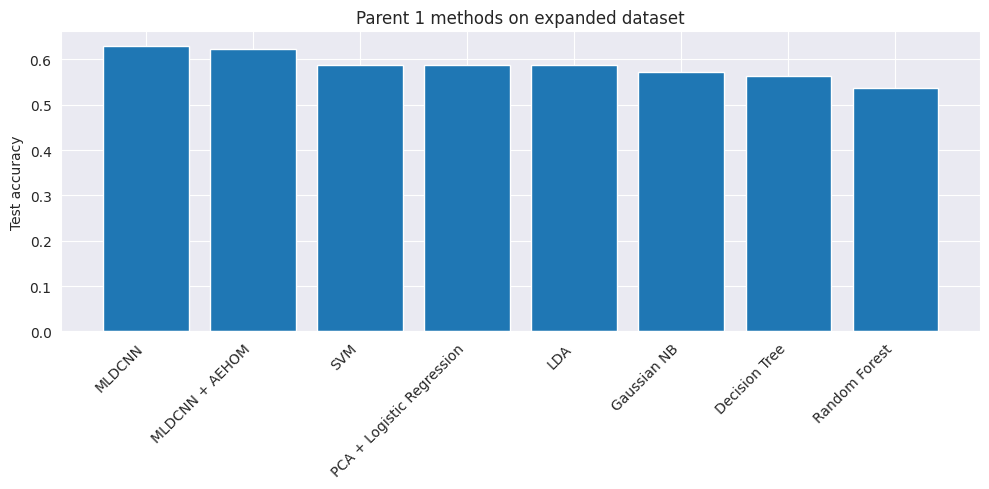

In [ ]:

def result_row(name,pred,prob=None):
    cm=confusion_matrix(y_test,pred)
    return {
        "Model":name,
        "Accuracy":accuracy_score(y_test,pred),
        "Precision":precision_score(y_test,pred,zero_division=0),
        "Recall/TPR":recall_score(y_test,pred,zero_division=0),
        "F1":f1_score(y_test,pred,zero_division=0),
        "Specificity":cm[0,0]/max(1,cm[0].sum()),
        "AUC":roc_auc_score(y_test,prob) if prob is not None else np.nan
    }

p1_final=pd.DataFrame(
    p1_results+
    [result_row("MLDCNN",mld_pred,mld_prob),
     result_row("MLDCNN + AEHOM",aeho_pred,aeho_prob)]
).sort_values("Accuracy",ascending=False)

display(p1_final)

plt.figure(figsize=(10,5))
plt.bar(p1_final["Model"],p1_final["Accuracy"])
plt.xticks(rotation=45,ha="right")
plt.ylabel("Test accuracy")
plt.title("Parent 1 methods on expanded dataset")
plt.tight_layout()
plt.show()
